# Clasificación de sentimientos de reseñas de IMDb con redes neuronales recurrentes: versión 2 (mejorada)

**Miniproyecto 2 · Técnicas de Deep Learning (MAIA-4213) · Maestría en Inteligencia Artificial, Universidad de los Andes**

**Autores:** Miguel Muñoz, David Cardenas y Mario Celis

**Objetivo (enunciado):** desarrollar un método basado en redes neuronales recurrentes que clasifique con precisión las reseñas de películas de IMDb como **positivas** o **negativas**.

**Punto de partida.** Este notebook extiende `01_solucion_rnn_imdb.ipynb` (versión 1). Conserva la misma partición (`data/splits/split.csv`), la misma limpieza, el mismo vocabulario y el mismo protocolo de entrenamiento, de modo que los resultados de ambas versiones se pueden comparar directamente. El análisis de la versión 1 dejó estas debilidades, que guían las mejoras:

| # | Debilidad de la versión 1 | Mejora en esta versión | Sección |
|---|---|---|---|
| 1 | Solo embeddings Word2Vec entrenados en el dominio; GloVe (mencionado en el enunciado) no se probó | Comparación **Word2Vec vs GloVe** preentrenado (Wikipedia + Gigaword), con manejo de contracciones | 3, 7 |
| 2 | Comparaciones de arquitectura con **una sola semilla** | Todos los experimentos con **3 semillas** (media ± desviación estándar) | 7 a 9 |
| 3 | Sobreajuste desde la época 5; el embedding concentra el 97 % de los parámetros | Experimento de **embedding congelado vs entrenable** | 8 |
| 4 | Umbral fijo de 0,5: 375 falsos positivos frente a 175 falsos negativos | **Umbral ajustado en validación** | 10 |
| 5 | Probabilidades sobreconfiadas (159 errores con confianza > 0,9) | **Calibración por temperatura** y error de calibración esperado (ECE) | 10 |
| 6 | La línea base TF-IDF supera a la RNN y los errores solo coinciden en parte | **Ensambles**: promedio de semillas y RNN + TF-IDF, con pesos elegidos en validación | 10 |
| 7 | No se guardaban predicciones de validación; Word2Vec no determinista | Se guardan predicciones de validación y prueba; Word2Vec con un hilo y *hash* fijo | 0, 3, 6 |

**Alcance y cómputo.** Todo se entrena en CPU de 2 núcleos. En este entorno una época con 200 tokens tarda unos 5 minutos y una corrida completa con 400 tokens unas 2 horas. Por eso, todos los experimentos de esta versión usan **200 tokens con 3 semillas**: se priorizó la robustez estadística sobre la longitud. La configuración final de la versión 1 (400 tokens) queda como referencia en la tabla comparativa de la sección 11.

**Regla general:** toda decisión (embedding, congelar o no, longitud, umbral, temperatura, peso del ensamble) se toma con el conjunto de **validación**. El conjunto de **prueba** solo se usa para reportar.

**Flujo:** configuración → datos y partición (idéntica a v1) → vocabulario → Word2Vec y GloVe → pipeline → arquitectura → entrenamiento y línea base → experimento 1 (embeddings) → experimento 2 (congelar) → configuración final → umbral, calibración y ensambles → resultados cuantitativos y cualitativos → figuras y cifras → discusión.

## 0. Configuración y reproducibilidad

In [1]:
import os, re, html, json, time, random, copy, platform, collections, gzip, zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss,
                             confusion_matrix, classification_report, roc_curve)
from gensim.models import Word2Vec
import gensim

# Raíz del repositorio (funciona desde notebooks/ o desde la raíz)
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw" / "movie.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "data" / "raw" / "movie.csv").exists(), "Ejecute el notebook dentro del repositorio."

QUICK = os.environ.get("MP2_QUICK", "0") == "1"   # prueba de humo: subconjunto y 1 época
RETRAIN = False                                   # True: reentrena aunque existan resultados guardados

# Las salidas de la versión 2 van a subcarpetas v2/ para no sobrescribir las de la versión 1
if QUICK:
    BASE_OUT = ROOT / "outputs" / "_smoke_test_v2"
    TAB, FIG, MODELS = BASE_OUT / "tables", BASE_OUT / "figures", BASE_OUT / "models"
else:
    TAB, FIG, MODELS = ROOT / "outputs/tables/v2", ROOT / "outputs/figures/v2", ROOT / "outputs/models/v2"
RUNS = TAB / "runs"
SPLITS = ROOT / "data" / "splits"
GLOVE_PATH = ROOT / "data" / "external" / "glove-wiki-gigaword-100.gz"
REPORT_FIGS = FIG / "informe" if QUICK else ROOT / "report" / "figs"
for d in [TAB, FIG, MODELS, RUNS, REPORT_FIGS]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    seed=42,
    min_freq=2, max_vocab=20000,         # vocabulario construido solo con train (igual que v1)
    max_len=200,                         # tokens por reseña en los experimentos 1 y 2
    max_len_v1_final=400,                # longitud de la configuración final de v1 (solo como referencia)
    truncado="inicio+final",             # elegido en v1 (sección 7.1) por F1 de validación
    emb_dim=100,                         # Word2Vec y GloVe con la misma dimensión: comparación justa
    w2v_window=5, w2v_epochs=5, w2v_sg=1,
    cell="gru", hidden=64, bidirectional=True, dropout=0.3, pooling="media+max",   # mejor arquitectura de v1
    batch_size=128, lr=1e-3, weight_decay=0.0, clip=1.0,
    max_epochs=10, patience=3, lr_factor=0.5, lr_patience=1,
    seeds=[42, 7, 123],
)
if QUICK:
    CONFIG.update(max_epochs=1, seeds=[42, 7])

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(max(1, os.cpu_count() or 1))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["seed"])
VERSIONS = {"python": platform.python_version(), "torch": torch.__version__, "gensim": gensim.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()))
print("Dispositivo:", DEVICE, "| hilos CPU:", torch.get_num_threads(), "| modo rápido:", QUICK)
print(json.dumps(CONFIG, indent=1))

python 3.13.18 | torch 2.15.0+cu132 | gensim 4.4.0 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1
Dispositivo: cpu | hilos CPU: 2 | modo rápido: False
{
 "seed": 42,
 "min_freq": 2,
 "max_vocab": 20000,
 "max_len": 200,
 "max_len_v1_final": 400,
 "truncado": "inicio+final",
 "emb_dim": 100,
 "w2v_window": 5,
 "w2v_epochs": 5,
 "w2v_sg": 1,
 "cell": "gru",
 "hidden": 64,
 "bidirectional": true,
 "dropout": 0.3,
 "pooling": "media+max",
 "batch_size": 128,
 "lr": 0.001,
 "weight_decay": 0.0,
 "clip": 1.0,
 "max_epochs": 10,
 "patience": 3,
 "lr_factor": 0.5,
 "lr_patience": 1,
 "seeds": [
  42,
  7,
  123
 ]
}


**Qué se mantiene de la versión 1 y por qué.** La arquitectura base (BiGRU, 64 unidades por dirección, resumen promedio + máximo) y el truncamiento *inicio+final* fueron las mejores opciones en validación de la versión 1. No se vuelven a explorar, para concentrar el cómputo en las debilidades pendientes. Se usan 200 tokens en lugar de 400 porque cuestan unas 3 veces menos por corrida, lo que permite entrenar 3 semillas por configuración. El costo es conocido: en la versión 1, pasar de 200 a 400 tokens subió la F1 de prueba de 0,9032 a 0,9109 (una sola semilla).

## 1. Datos, limpieza y partición (idénticos a la versión 1)

Se repite exactamente el preprocesamiento de la versión 1:
- Se decodifican las entidades HTML, se eliminan las etiquetas y se pasa todo a minúsculas.
- La tokenización conserva las negaciones y contracciones (`didn't`) y los signos `!` y `?`.
- Se eliminan los duplicados detectados después de la limpieza.
- Se **carga** la partición estratificada 70/15/15 guardada en `data/splits/split.csv`.

El análisis exploratorio completo está en la sección 1 de la versión 1. Aquí solo se verifican las cifras clave.

In [2]:
raw = pd.read_csv(ROOT / "data/raw/movie.csv", encoding="utf-8-sig")
raw["id"] = np.arange(len(raw))

TOKEN_RE = re.compile(r"[a-z0-9à-ÿ]+(?:'[a-z]+)?|[!?]")

def clean_text(t: str) -> str:
    t = html.unescape(t)
    t = re.sub(r"<br\s*/?>", " ", t, flags=re.I)
    t = re.sub(r"<[^>]+>", " ", t)
    return t.lower().replace("’", "'").replace("`", "'")

def tokenize(t: str) -> list:
    return TOKEN_RE.findall(clean_text(t))

raw["tokens"] = raw.text.map(tokenize)
raw["n_tokens"] = raw.tokens.str.len()
raw["clave"] = raw.tokens.str.join(" ")
dup_mask = raw.duplicated("clave")
df = raw[~dup_mask].reset_index(drop=True)

SPLIT_PATH = SPLITS / "split.csv"
assert SPLIT_PATH.exists(), "Falta data/splits/split.csv (se genera en la versión 1)"
split = pd.read_csv(SPLIT_PATH)
df = df.merge(split, on="id")
assert df.groupby("clave").split.nunique().max() == 1, "Hay textos repetidos entre particiones"

tabla = pd.crosstab(df.split, df.label).loc[["train", "val", "test"]].rename(columns={0: "negativa", 1: "positiva"})
tabla["total"] = tabla.sum(axis=1); tabla["%"] = (100 * tabla.total / tabla.total.sum()).round(1)
print(f"Reseñas: {len(raw)} | duplicados eliminados: {int(dup_mask.sum())} | únicas: {len(df)}")
display(tabla)
print("Verificación: ningún texto aparece en más de una partición.")

if QUICK:
    df = pd.concat([g.sample(min(len(g), {"train": 2000, "val": 500, "test": 500}[s]), random_state=0)
                    for s, g in df.groupby("split")])
    print("MODO RÁPIDO:", df.split.value_counts().to_dict())

TR, VA, TE = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])

Reseñas: 40000 | duplicados eliminados: 280 | únicas: 39720


label,negativa,positiva,total,%
split,,,,
train,13869,13935,27804,70.0
val,2972,2986,5958,15.0
test,2972,2986,5958,15.0


Verificación: ningún texto aparece en más de una partición.


## 2. Vocabulario y truncamiento

El vocabulario se construye **solo con entrenamiento**: palabras con frecuencia ≥ 2, hasta 20 000 términos. El índice 0 es `<pad>` y el 1 es `<unk>`. Las reseñas más largas que `max_len` conservan el inicio (¼) y el final (¾), la estrategia ganadora en la versión 1.

In [3]:
counter = collections.Counter(t for toks in TR.tokens for t in toks)
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common(CONFIG["max_vocab"]) if c >= CONFIG["min_freq"]]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
print(f"Tokens distintos en train: {len(counter):,} | vocabulario: {V:,}")
for L in [CONFIG["max_len"], CONFIG["max_len_v1_final"]]:
    print(f"Reseñas de train con <= {L} tokens (se ven completas): {(TR.n_tokens <= L).mean():.1%}")

def truncate(tokens, mode=CONFIG["truncado"], L=CONFIG["max_len"]):
    if len(tokens) <= L or mode == "completa":
        return tokens
    if mode == "inicio":
        return tokens[:L]
    if mode == "final":
        return tokens[-L:]
    if mode == "inicio+final":
        h = L // 4
        return tokens[:h] + tokens[-(L - h):]
    raise ValueError(mode)

Tokens distintos en train: 87,969 | vocabulario: 20,002
Reseñas de train con <= 200 tokens (se ven completas): 58.3%
Reseñas de train con <= 400 tokens (se ven completas): 86.7%


## 3. Embeddings: Word2Vec en el dominio y GloVe preentrenado

Se construyen dos matrices de inicialización de `V × 100` para el mismo vocabulario:

- **Word2Vec** [3] (*skip-gram*, ventana 5, 5 épocas) entrenado **solo con las reseñas de entrenamiento**, como en la versión 1. Ahora se entrena con **un solo hilo** y una función *hash* fija, para que la matriz sea reproducible bit a bit (con varios hilos, gensim no es determinista).
- **GloVe** [11] `glove-wiki-gigaword-100`: 400 000 palabras en minúsculas, entrenado sobre Wikipedia 2014 y Gigaword 5 (6 000 millones de tokens). Es externo a IMDb, así que no filtra información de validación ni de prueba. Aporta conocimiento general del idioma que 28 000 reseñas no contienen. Su desventaja es que no conoce la jerga propia de las reseñas.

**Contracciones.** GloVe separa las contracciones (`did` + `n't`), mientras que nuestro tokenizador las conserva como una sola palabra (`didn't`), porque las negaciones invierten el sentimiento. Para no perder los vectores de las negaciones, una palabra con apóstrofo que no esté en GloVe recibe el promedio de los vectores de sus partes: `didn't` → (`did` + `n't`)/2 y `it's` → (`it` + `'s`)/2. Las palabras que siguen sin vector se inicializan al azar con la escala de GloVe.

El archivo de GloVe (128 MB, formato de `gensim-data`) se descarga una vez en `data/external/` y no se versiona.

In [4]:
def crc_hash(s):                                    # hash determinista (el hash de Python cambia por proceso)
    return zlib.crc32(str(s).encode("utf-8"))

W2V_PATH = MODELS / "w2v_embeddings.npy"
if W2V_PATH.exists() and not RETRAIN and not QUICK:
    EMB_W2V = np.load(W2V_PATH)
    print("Matriz Word2Vec cargada:", EMB_W2V.shape)
else:
    t0 = time.time()
    w2v = Word2Vec(sentences=TR.tokens.tolist(), vector_size=CONFIG["emb_dim"], window=CONFIG["w2v_window"],
                   min_count=CONFIG["min_freq"], sg=CONFIG["w2v_sg"], epochs=CONFIG["w2v_epochs"],
                   workers=1, seed=CONFIG["seed"], hashfxn=crc_hash)
    rng = np.random.default_rng(CONFIG["seed"])
    EMB_W2V = rng.normal(0, 0.1, (V, CONFIG["emb_dim"])).astype(np.float32)
    EMB_W2V[0] = 0.0                                            # <pad>
    hits_w2v = sum(1 for w in itos if w in w2v.wv)
    for w, i in stoi.items():
        if w in w2v.wv:
            EMB_W2V[i] = w2v.wv[w]
    print(f"Word2Vec entrenado en {time.time() - t0:.0f} s | cobertura del vocabulario: {hits_w2v / V:.1%}")
    np.save(W2V_PATH, EMB_W2V)

Matriz Word2Vec cargada: (20002, 100)


In [5]:
GLOVE_NPY = MODELS / "glove_embeddings.npy"
GLOVE_STATS = TAB / "glove_cobertura.json"
if GLOVE_NPY.exists() and GLOVE_STATS.exists() and not RETRAIN and not QUICK:
    EMB_GLOVE = np.load(GLOVE_NPY); glove_stats = json.loads(GLOVE_STATS.read_text())
    print("Matriz GloVe cargada:", EMB_GLOVE.shape)
else:
    assert GLOVE_PATH.exists(), (
        "Descargue GloVe 100d en data/external/: https://github.com/RaRe-Technologies/gensim-data/releases/"
        "download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz")
    t0 = time.time(); glove = {}
    with gzip.open(GLOVE_PATH, "rt", encoding="utf-8") as fh:
        next(fh)                                                # cabecera "400000 100"
        for line in fh:
            w, rest = line.split(" ", 1)
            glove[w] = rest
    def gvec(w):
        return np.array(glove[w].split(), dtype=np.float32)
    allv = np.stack([gvec(w) for w in list(glove)[:50000]])   # escala de referencia
    rng = np.random.default_rng(CONFIG["seed"])
    EMB_GLOVE = rng.normal(0, allv.std(), (V, CONFIG["emb_dim"])).astype(np.float32)
    EMB_GLOVE[0] = 0.0
    directo = partes = 0
    for w, i in stoi.items():
        if i < 2:
            continue
        if w in glove:
            EMB_GLOVE[i] = gvec(w); directo += 1
        elif "'" in w:                                          # contracciones: didn't -> did + n't
            a, b = w.split("'", 1)
            pieces = [a[:-1], "n't"] if b == "t" and a.endswith("n") else [a, "'" + b]
            pieces = [p for p in pieces if p in glove]
            if pieces:
                EMB_GLOVE[i] = np.mean([gvec(p) for p in pieces], axis=0); partes += 1
    glove_stats = dict(palabras_glove=len(glove), cobertura_directa=directo / (V - 2),
                       cobertura_con_contracciones=(directo + partes) / (V - 2), contracciones_resueltas=partes)
    del glove
    np.save(GLOVE_NPY, EMB_GLOVE); GLOVE_STATS.write_text(json.dumps(glove_stats, indent=1))
    print(f"GloVe procesado en {time.time() - t0:.0f} s")
print(f"Cobertura del vocabulario con GloVe: {glove_stats['cobertura_directa']:.1%} directa, "
      f"{glove_stats['cobertura_con_contracciones']:.1%} con contracciones "
      f"({glove_stats['contracciones_resueltas']} contracciones resueltas por partes)")

EMB_INIT = {"word2vec": EMB_W2V, "glove": EMB_GLOVE}

# Verificación cualitativa: vecinos más cercanos (coseno) en cada espacio
def vecinos(E, palabras, k=6):
    En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-8)
    return {w: ", ".join(itos[j] for j in np.argsort(-(En @ En[stoi[w]]))[1:k + 1]) for w in palabras if w in stoi}
palabras = ["excellent", "terrible", "boring", "masterpiece", "didn't", "waste"]
display(pd.DataFrame({"Word2Vec (IMDb train)": vecinos(EMB_W2V, palabras), "GloVe (Wikipedia + Gigaword)": vecinos(EMB_GLOVE, palabras)}))

Matriz GloVe cargada: (20002, 100)
Cobertura del vocabulario con GloVe: 96.6% directa, 99.6% con contracciones (592 contracciones resueltas por partes)


,Word2Vec (IMDb train),GloVe (Wikipedia + Gigaword)
excellent,"outstanding, superb, exceptional, fantastic, a...","good, quality, terrific, superb, best, impressive"
terrible,"horrible, horrid, awful, dreadful, horrendous,...","horrible, awful, dreadful, horrendous, horrifi..."
boring,"dull, pointless, tedious, unoriginal, predicta...","tedious, dull, bored, funny, stupid, downright"
masterpiece,"masterwork, classic, milestone, miyazaki's, ci...","masterpieces, masterwork, cinematic, anthology..."
didn't,"don't, didnt, doesn't, wouldn't, couldn't, doesnt","did, couldn't, wouldn't, don't, doesn't, shoul..."
waste,"wasting, wasted, waster, celluloid, wastes, waist","wastes, disposal, garbage, recycling, toxic, t..."


## 4. Pipeline de datos: secuencias numéricas y lotes

Es el mismo de la versión 1. Cada reseña se convierte en índices del vocabulario, truncada a `max_len`. Los lotes agrupan reseñas de longitud parecida (*bucketing*) y `pack_padded_sequence` evita procesar el relleno.

In [6]:
class ReviewDataset(Dataset):
    def __init__(self, frame, max_len):
        self.seqs = [[stoi.get(t, 1) for t in truncate(toks, CONFIG["truncado"], max_len)] or [1] for toks in frame.tokens]
        self.labels = frame.label.values.astype(np.float32)
        self.ids = frame.id.values
    def __len__(self):
        return len(self.seqs)
    def __getitem__(self, i):
        return self.seqs[i], self.labels[i]

class BucketBatchSampler(Sampler):
    # Agrupa índices de longitud similar; baraja el orden de los lotes en cada época
    def __init__(self, lengths, batch_size, shuffle, seed):
        self.lengths, self.bs, self.shuffle, self.seed, self.epoch = np.asarray(lengths), batch_size, shuffle, seed, 0
    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch); self.epoch += 1
        idx = rng.permutation(len(self.lengths)) if self.shuffle else np.arange(len(self.lengths))
        chunk = self.bs * 50
        batches = []
        for s in range(0, len(idx), chunk):
            c = idx[s:s + chunk]
            c = c[np.argsort(-self.lengths[c], kind="stable")]
            batches += [c[j:j + self.bs].tolist() for j in range(0, len(c), self.bs)]
        if self.shuffle:
            rng.shuffle(batches)
        return iter(batches)
    def __len__(self):
        return int(np.ceil(len(self.lengths) / self.bs))

def collate(batch):
    seqs, ys = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    x = torch.zeros(len(seqs), int(lengths.max()), dtype=torch.long)
    for i, s in enumerate(seqs):
        x[i, :len(s)] = torch.tensor(s)
    return x, lengths, torch.tensor(ys)

def make_loader(frame, shuffle, max_len, seed=42):
    ds = ReviewDataset(frame, max_len)
    sampler = BucketBatchSampler([len(s) for s in ds.seqs], CONFIG["batch_size"], shuffle, seed)
    return DataLoader(ds, batch_sampler=sampler, collate_fn=collate, num_workers=0)

x, l, y = next(iter(make_loader(TR, True, CONFIG["max_len"])))
print("Lote de ejemplo:", tuple(x.shape), "| longitudes", l[:6].tolist(), "| etiquetas", y[:6].tolist())
print("Reseña -> índices:", x[0, :12].tolist(), "->", [itos[i] for i in x[0, :12].tolist()])

Lote de ejemplo: (128, 200) | longitudes [200, 200, 200, 200, 200, 200] | etiquetas [1.0, 1.0, 1.0, 0.0, 1.0, 0.0]
Reseña -> índices: [1330, 6304, 284, 3, 955, 961, 375, 261, 35, 2, 4042, 2119] -> ['bruce', 'almighty', 'looks', 'and', 'sounds', 'incredibly', 'stupid', 'especially', 'from', 'the', 'trailers', 'nevertheless']


## 5. Arquitectura

```
Índices (B × T)
 └─ Embedding V × 100 (Word2Vec, GloVe o aleatorio; entrenable o congelado; padding_idx = 0) → Dropout 0,3
 └─ GRU bidireccional, 1 capa, 64 unidades por dirección (secuencias empaquetadas)
 └─ Resumen de la secuencia: promedio y máximo de las salidas de todos los pasos reales (256) → Dropout 0,3
 └─ Densa → 1 → sigmoide → P(positiva)
```

**Justificación de cada capa** (detallada en la sección 6 de la versión 1):
- **Embedding.** Convierte índices en vectores densos. Se inicializa con conocimiento previo (Word2Vec o GloVe) y `padding_idx` anula el gradiente del relleno. La novedad de esta versión es la opción `congelar_emb`. Al congelar el embedding, la red pasa de ~2,06 M a ~64 k parámetros entrenables. Es una regularización fuerte contra el sobreajuste observado en la versión 1, a cambio de no adaptar los vectores a la tarea.
- **Dropout** [8] sobre los embeddings y antes de la salida.
- **GRU bidireccional** [2], [5]. Las compuertas mitigan el desvanecimiento del gradiente [10] y la dirección inversa conserva el inicio de la reseña. GRU superó a LSTM en la versión 1 con un 25 % menos de parámetros recurrentes.
- **Promedio + máximo.** El máximo retiene expresiones fuertes aunque aparezcan a mitad de una reseña larga. Superó al estado final en validación en la versión 1.
- **Densa con sigmoide.** Da P(positiva), como sugiere el enunciado. En el entrenamiento la sigmoide va dentro de `BCEWithLogitsLoss`, que es numéricamente más estable.

In [7]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, cell="gru", bidirectional=True, dropout=0.3, emb_weights=None,
                 pooling="media+max", freeze_emb=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if emb_weights is not None:
            with torch.no_grad():
                self.emb.weight.copy_(torch.as_tensor(emb_weights))
        self.emb.weight.requires_grad_(not freeze_emb)
        self.emb_drop = nn.Dropout(dropout)
        rnn_cls = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn_cls(emb_dim, hidden, num_layers=1, batch_first=True, bidirectional=bidirectional)
        self.bidirectional, self.pooling = bidirectional, pooling
        d = hidden * (2 if bidirectional else 1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(d * (2 if pooling == "media+max" else 1), 1)

    def forward(self, x, lengths):
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        if self.pooling == "final":
            h = h[0] if isinstance(h, tuple) else h
            z = torch.cat([h[-2], h[-1]], dim=1) if self.bidirectional else h[-1]
        else:                                              # promedio y máximo sobre los pasos reales (sin relleno)
            out, _ = pad_packed_sequence(out, batch_first=True)
            L = lengths.to(out.device)
            mask = (torch.arange(out.size(1), device=out.device)[None, :] < L[:, None]).unsqueeze(-1)
            mean = (out * mask).sum(1) / L[:, None]
            mx = out.masked_fill(~mask, -1e4).max(1).values
            z = torch.cat([mean, mx], dim=1)
        return self.fc(self.drop(z)).squeeze(1)            # logit; sigmoide en la pérdida / inferencia

for freeze in [False, True]:
    m = SentimentRNN(V, CONFIG["emb_dim"], CONFIG["hidden"], freeze_emb=freeze)
    n_tot = sum(p.numel() for p in m.parameters()); n_tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"Embedding {'congelado ' if freeze else 'entrenable'}: {n_tot:,} parámetros, {n_tr:,} entrenables")

Embedding entrenable: 2,064,201 parámetros, 2,064,201 entrenables
Embedding congelado : 2,064,201 parámetros, 64,001 entrenables


## 6. Entrenamiento, métricas y línea base

**Protocolo (igual que en la versión 1):**
- Pérdida BCE con logits, Adam [9] con lr 10⁻³ y lotes de 128.
- *Gradient clipping* con norma 1 [7].
- *ReduceLROnPlateau* (×0,5 si la F1 de validación no mejora en una época).
- Máximo 10 épocas con *early stopping* (paciencia 3) sobre la **F1 de validación**. Se conserva la mejor época.

**Novedad.** Cada corrida guarda en `outputs/tables/v2/runs/` sus predicciones de **validación y prueba**. Con las de validación se ajustan el umbral, la temperatura y los ensambles (sección 11) sin tocar la prueba. Si una corrida se interrumpe, se reanuda desde la última época guardada.

**Métricas** (clase positiva = 1): precision, recall y F1 (las que pide el enunciado), *accuracy*, F1-macro, ROC-AUC y matriz de confusión. Además, el error de calibración esperado (ECE, 15 intervalos) mide qué tan confiables son las probabilidades.

In [8]:
def compute_metrics(y, prob, thr=0.5):
    y = np.asarray(y).astype(int); prob = np.asarray(prob); pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
                f1_macro=f1_score(y, pred, average="macro", zero_division=0), roc_auc=roc_auc_score(y, prob),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def ece(y, prob, bins=15):
    # Error de calibración esperado: |confianza - acierto| promediado por intervalos de confianza
    y = np.asarray(y); prob = np.asarray(prob)
    conf = np.maximum(prob, 1 - prob); correct = ((prob >= 0.5).astype(int) == y)
    edges = np.linspace(0.5, 1.0, bins + 1); total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return float(total)

@torch.no_grad()
def predict(model, loader):
    model.eval(); probs, ys = [], []
    for x, lengths, y in loader:
        probs.append(torch.sigmoid(model(x.to(DEVICE), lengths)).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(probs).numpy()

def ordered_ids(loader):
    return np.concatenate([loader.dataset.ids[b] for b in loader.batch_sampler])

def tag_of(emb, freeze, max_len, seed, cell=CONFIG["cell"], pooling=CONFIG["pooling"]):
    return f"{cell}_{emb}{'-congelado' if freeze else ''}_{'mm' if pooling == 'media+max' else 'final'}_L{max_len}_s{seed}"

EMB_NAME = {"word2vec": "Word2Vec", "glove": "GloVe", "aleatorio": "aleatorio"}
def nice(r):
    emb = EMB_NAME[r["emb"]]
    return f"Bi{r['cell'].upper()} {emb}{' congelado' if r['congelado'] else ''} L{r['max_len']}"

def run_experiment(emb, seed, freeze=False, max_len=CONFIG["max_len"]):
    tag = tag_of(emb, freeze, max_len, seed)
    res_path, hist_path = RUNS / f"{tag}.json", RUNS / f"{tag}_historia.csv"
    pv_path, pt_path = RUNS / f"{tag}_pred_val.csv", RUNS / f"{tag}_pred_test.csv"
    if res_path.exists() and not RETRAIN:
        res = json.loads(res_path.read_text())
        print(f"[{tag}] resultados cargados (entrenado en {res['tiempo_min']:.1f} min en {res['dispositivo']}; "
              f"mejor época {res['mejor_epoca']} de {res['epocas']}). Historia de entrenamiento:")
        hist = pd.read_csv(hist_path); display(hist.round(4))
        return res, hist, pd.read_csv(pv_path), pd.read_csv(pt_path)

    set_seed(seed)
    tr_dl = make_loader(TR, True, max_len, seed)
    va_dl, te_dl = make_loader(VA, False, max_len), make_loader(TE, False, max_len)
    model = SentimentRNN(V, CONFIG["emb_dim"], CONFIG["hidden"], CONFIG["cell"], CONFIG["bidirectional"], CONFIG["dropout"],
                         EMB_INIT.get(emb), CONFIG["pooling"], freeze).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=CONFIG["lr_factor"], patience=CONFIG["lr_patience"])
    ckpt_path = MODELS / f"{tag}_ckpt.pt"
    hist, best, best_state, wait, start_ep, elapsed = [], -1.0, None, 0, 1, 0.0
    if ckpt_path.exists() and not RETRAIN:                 # reanuda un entrenamiento interrumpido
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        hist, best, best_state, wait = ck["hist"], ck["best"], ck["best_state"], ck["wait"]
        start_ep, elapsed = ck["epoch"] + 1, ck["elapsed"]
        tr_dl.batch_sampler.epoch = ck["epoch"]
        set_seed(seed + 1000 * ck["epoch"])                # estado aleatorio reproducible al reanudar
        print(f"[{tag}] reanudando desde la época {start_ep}")
    for ep in range(start_ep, CONFIG["max_epochs"] + 1):
        if wait >= CONFIG["patience"]:
            break
        t0 = time.time(); model.train(); tl, tc, tn = 0.0, 0, 0
        lr_ep = opt.param_groups[0]["lr"]
        for x, lengths, y in tr_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x, lengths)
            loss = F.binary_cross_entropy_with_logits(logits, y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(params, CONFIG["clip"]); opt.step()
            tl += loss.item() * len(y); tc += ((logits > 0).float() == y).sum().item(); tn += len(y)
        yv, pv = predict(model, va_dl); mv = compute_metrics(yv, pv)
        vloss = log_loss(yv, np.clip(pv, 1e-7, 1 - 1e-7), labels=[0, 1])
        sched.step(mv["f1"])
        elapsed += time.time() - t0
        hist.append(dict(epoch=ep, lr=lr_ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vloss,
                         val_acc=mv["accuracy"], val_f1=mv["f1"], seg=time.time() - t0))
        mejora = mv["f1"] > best
        if mejora:
            best, best_state, wait = mv["f1"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
        linea = (f"[{tag}] ép {ep} | lr {lr_ep:.1e} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vloss:.4f} "
                 f"acc {mv['accuracy']:.4f} F1 {mv['f1']:.4f} | {time.time() - t0:.0f}s{' *' if mejora else ''}")
        print(linea, flush=True)
        with open(TAB / "entrenamiento.log", "a", encoding="utf-8") as fh:
            fh.write(time.strftime("%Y-%m-%d %H:%M:%S ") + linea + "\n")
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), hist=hist, best=best,
                        best_state=best_state, wait=wait, epoch=ep, elapsed=elapsed), ckpt_path)
    hist = pd.DataFrame(hist)
    model.load_state_dict(best_state)
    torch.save(best_state, MODELS / f"{tag}.pt")
    yv, pv = predict(model, va_dl); yt, pt = predict(model, te_dl)
    pred_val = pd.DataFrame({"id": ordered_ids(va_dl), "y": yv.astype(int), "prob": pv})
    pred_test = pd.DataFrame({"id": ordered_ids(te_dl), "y": yt.astype(int), "prob": pt})
    best_row = hist.loc[hist.val_f1.idxmax()]
    res = dict(tag=tag, cell=CONFIG["cell"], emb=emb, congelado=freeze, pooling=CONFIG["pooling"], max_len=max_len,
               seed=seed, mejor_epoca=int(best_row.epoch), epocas=int(len(hist)), train_acc=float(best_row.train_acc),
               val_acc=float(best_row.val_acc), val_f1=float(best_row.val_f1), val_loss=float(best_row.val_loss),
               tiempo_min=elapsed / 60, dispositivo=str(DEVICE),
               parametros=int(sum(p.numel() for p in model.parameters())),
               parametros_entrenables=int(sum(p.numel() for p in model.parameters() if p.requires_grad)),
               **{f"test_{k}": float(v) for k, v in compute_metrics(yt, pt).items()})
    hist.to_csv(hist_path, index=False); pred_val.to_csv(pv_path, index=False); pred_test.to_csv(pt_path, index=False)
    res_path.write_text(json.dumps(res, indent=1))
    ckpt_path.unlink(missing_ok=True)
    return res, hist, pred_val, pred_test

RESULTS, HIST, PVAL, PTEST = {}, {}, {}, {}
def run_and_store(**kw):
    res, h, pv, pt = run_experiment(**kw)
    RESULTS[res["tag"]], HIST[res["tag"]], PVAL[res["tag"]], PTEST[res["tag"]] = res, h, pv, pt
    return res

### 6.1 Línea base: TF-IDF + regresión logística

Es la misma línea base de la versión 1: TF-IDF de unigramas y bigramas sobre la reseña completa y C elegido en validación. Se recalcula aquí para obtener también sus probabilidades en **validación**, que se necesitan para ajustar el ensamble RNN + TF-IDF sin usar la prueba.

In [9]:
def tfidf_lr(train_docs, y_train, eval_docs, C):
    vec = TfidfVectorizer(analyzer=lambda d: d, min_df=2, max_features=200_000, sublinear_tf=True)
    add_bi = lambda toks: toks + [a + " " + b for a, b in zip(toks, toks[1:])]
    Xtr = vec.fit_transform([add_bi(t) for t in train_docs]); clf = LogisticRegression(C=C, max_iter=2000)
    clf.fit(Xtr, y_train)
    return [clf.predict_proba(vec.transform([add_bi(t) for t in docs]))[:, 1] for docs in eval_docs]

t0 = time.time()
BASE_PATH = TAB / "linea_base_tfidf.json"
if BASE_PATH.exists() and not RETRAIN:
    base = json.loads(BASE_PATH.read_text())
    base_val, base_test = pd.read_csv(TAB / "linea_base_pred_val.csv"), pd.read_csv(TAB / "linea_base_pred_test.csv")
    print("Línea base cargada")
else:
    grid = []
    for C in [0.5, 1.0, 2.0, 4.0, 8.0]:
        (pv,) = tfidf_lr(TR.tokens, TR.label, [VA.tokens], C)
        grid.append((f1_score(VA.label, pv >= 0.5), C))
    best_f1, best_C = max(grid)
    pv, pt = tfidf_lr(TR.tokens, TR.label, [VA.tokens, TE.tokens], best_C)
    base = dict(modelo="TF-IDF (1-2 gramas) + regresión logística", C=best_C, val_f1=f1_score(VA.label, pv >= 0.5),
                **{f"test_{k}": float(v) for k, v in compute_metrics(TE.label, pt).items()})
    base_val = pd.DataFrame({"id": VA.id, "y": VA.label, "prob": pv})
    base_test = pd.DataFrame({"id": TE.id, "y": TE.label, "prob": pt})
    BASE_PATH.write_text(json.dumps(base, indent=1))
    base_val.to_csv(TAB / "linea_base_pred_val.csv", index=False); base_test.to_csv(TAB / "linea_base_pred_test.csv", index=False)
print(f"Línea base (C = {base['C']}): val F1 {base['val_f1']:.4f} | test F1 {base['test_f1']:.4f} | "
      f"test acc {base['test_accuracy']:.4f} | {time.time() - t0:.0f} s")

Línea base cargada
Línea base (C = 8.0): val F1 0.9136 | test F1 0.9187 | test acc 0.9183 | 0 s


## 7. Experimento 1: Word2Vec en el dominio vs GloVe preentrenado (3 semillas)

Se usa la arquitectura base (BiGRU, promedio + máximo, embedding entrenable, 200 tokens) con semillas {42, 7, 123}. Solo cambia la inicialización del embedding. La elección se hace por **F1 media de validación**.

**Hipótesis.** GloVe aporta semántica general aprendida de 6 000 millones de tokens, que podría ayudar con palabras poco frecuentes en las 28 000 reseñas. Word2Vec, en cambio, refleja el uso específico de las palabras en el cine (por ejemplo, *cheesy* o *oscar*). No es evidente cuál conviene más, por eso se prueban ambas.

In [10]:
for emb in ["word2vec", "glove"]:
    for seed in CONFIG["seeds"]:
        run_and_store(emb=emb, seed=seed)

show_cols = ["seed", "parametros_entrenables", "mejor_epoca", "epocas", "train_acc", "val_acc", "val_f1", "test_precision",
             "test_recall", "test_f1", "test_roc_auc", "tiempo_min"]
agg_cols = ["val_f1", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]

def tabla_exp(tags):
    t = pd.DataFrame([RESULTS[k] for k in tags])
    t["configuracion"] = t.apply(nice, axis=1)
    return t

def media_std(t):
    g = t.groupby("configuracion", sort=False)[agg_cols]
    out = g.mean().map("{:.4f}".format) + " ± " + g.std().map("{:.4f}".format)
    return out

E1_TAGS = [tag_of(e, False, CONFIG["max_len"], s) for e in ["word2vec", "glove"] for s in CONFIG["seeds"]]
e1 = tabla_exp(E1_TAGS)
display(e1.set_index("configuracion")[show_cols].round(4))
e1_ms = media_std(e1); display(e1_ms)
e1.to_csv(TAB / "exp1_embeddings.csv", index=False); e1_ms.to_csv(TAB / "exp1_embeddings_media_std.csv")
BEST_EMB = e1.groupby("emb").val_f1.mean().idxmax()
print(f"Mejor embedding por F1 media de validación: {BEST_EMB} "
      f"({e1.groupby('emb').val_f1.mean().round(4).to_dict()})")

[gru_word2vec_mm_L200_s42] resultados cargados (entrenado en 40.0 min en cpu; mejor época 5 de 8). Historia de entrenamiento:


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.0010,0.4465,0.7781,0.3201,0.8659,0.8576,292.7820
1,2,0.0010,0.2671,0.8886,0.2558,0.8941,0.8946,297.2701
2,3,0.0010,0.2051,0.9190,0.3567,0.8726,0.8844,298.1809
3,4,0.0010,0.1654,0.9364,0.2808,0.8839,0.8767,311.1655
4,5,0.0005,0.1201,0.9569,0.2643,0.9030,0.9050,288.8441
5,6,0.0005,0.0982,0.9653,0.3166,0.8985,0.8991,295.1966
6,7,0.0005,0.0821,0.9721,0.3096,0.9003,0.9026,303.9642
7,8,0.0002,0.0651,0.9777,0.3586,0.8944,0.8913,311.8674


[gru_word2vec_mm_L200_s7] resultados cargados (entrenado en 35.1 min en cpu; mejor época 4 de 7). Historia de entrenamiento:


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.0010,0.4712,0.7589,0.2971,0.8748,0.8799,311.6496
1,2,0.0010,0.2707,0.8881,0.2566,0.8931,0.8957,285.6078
2,3,0.0010,0.2071,0.9170,0.2369,0.9003,0.8987,300.9808
3,4,0.0010,0.1616,0.9400,0.2595,0.9027,0.9056,306.9871
4,5,0.0010,0.1249,0.9530,0.2969,0.8889,0.8819,300.0592
5,6,0.0010,0.0944,0.9657,0.3163,0.8964,0.8979,298.7663
6,7,0.0005,0.0584,0.9796,0.3534,0.8946,0.8944,300.4092


[gru_word2vec_mm_L200_s123] resultados cargados (entrenado en 35.4 min en cpu; mejor época 4 de 7). Historia de entrenamiento:


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.0010,0.4509,0.7809,0.3270,0.8567,0.8688,308.0785
1,2,0.0010,0.2699,0.8880,0.2610,0.8902,0.8931,286.0271
2,3,0.0010,0.2118,0.9162,0.2430,0.8985,0.8997,305.7581
3,4,0.0010,0.1662,0.9362,0.2528,0.8974,0.9003,290.6123
4,5,0.0010,0.1310,0.9502,0.2649,0.8943,0.8920,293.7821
5,6,0.0010,0.0948,0.9652,0.3530,0.8902,0.8956,298.8804
6,7,0.0005,0.0649,0.9777,0.3516,0.8959,0.8971,339.3660


... (5 outputs left out)

,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.0010,0.5042,0.7389,0.5015,0.7847,0.8193,270.4431
1,2,0.0010,0.2893,0.8792,0.2690,0.8917,0.8919,273.3392
2,3,0.0010,0.2230,0.9107,0.2491,0.9005,0.9030,278.7606
3,4,0.0010,0.1809,0.9299,0.2778,0.8941,0.9002,282.4763
4,5,0.0010,0.1444,0.9457,0.2557,0.9015,0.9019,301.9312
5,6,0.0005,0.1104,0.9596,0.2702,0.9003,0.9011,310.9915


,seed,parametros_entrenables,mejor_epoca,epocas,train_acc,val_acc,val_f1,test_precision,test_recall,test_f1,test_roc_auc,tiempo_min
configuracion,,,,,,,,,,,,
BiGRU Word2Vec L200,42,2064201,5,8,0.9569,0.9030,0.9050,0.8920,0.9180,0.9048,0.9635,39.9878
BiGRU Word2Vec L200,7,2064201,4,7,0.9400,0.9027,0.9056,0.8847,0.9226,0.9033,0.9640,35.0743
BiGRU Word2Vec L200,123,2064201,4,7,0.9362,0.8974,0.9003,0.8907,0.9200,0.9051,0.9625,35.3751
BiGRU GloVe L200,42,2064201,4,7,0.9308,0.9068,0.9079,0.9037,0.9082,0.9060,0.9652,35.8530
BiGRU GloVe L200,7,2064201,4,7,0.9303,0.9045,0.9062,0.8947,0.9163,0.9054,0.9639,34.5333
BiGRU GloVe L200,123,2064201,3,6,0.9107,0.9005,0.9030,0.8865,0.9156,0.9008,0.9629,28.6324


,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
configuracion,,,,,,
BiGRU Word2Vec L200,0.9036 ± 0.0029,0.9025 ± 0.0013,0.8891 ± 0.0039,0.9202 ± 0.0024,0.9044 ± 0.0010,0.9633 ± 0.0008
BiGRU GloVe L200,0.9057 ± 0.0025,0.9028 ± 0.0034,0.8950 ± 0.0086,0.9134 ± 0.0045,0.9040 ± 0.0028,0.9640 ± 0.0012


Mejor embedding por F1 media de validación: glove ({'glove': 0.9057, 'word2vec': 0.9036})


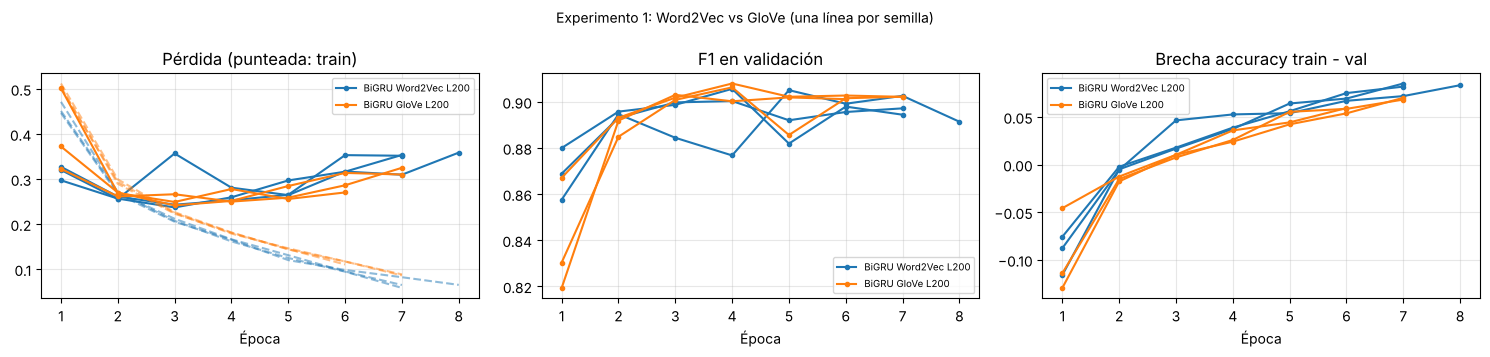

In [11]:
def plot_runs(tags, fname, titulo):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    confs = list(dict.fromkeys(nice(RESULTS[t]) for t in tags)); colors = dict(zip(confs, plt.cm.tab10.colors))
    for tag in tags:
        h, r = HIST[tag], RESULTS[tag]; c = colors[nice(r)]
        lab = nice(r) if r["seed"] == CONFIG["seeds"][0] else None
        ax[0].plot(h.epoch, h.val_loss, marker="o", ms=3, color=c, label=lab)
        ax[0].plot(h.epoch, h.train_loss, ls="--", color=c, alpha=0.5)
        ax[1].plot(h.epoch, h.val_f1, marker="o", ms=3, color=c, label=lab)
        ax[2].plot(h.epoch, h.train_acc - h.val_acc, marker="o", ms=3, color=c, label=lab)
    ax[0].set_title("Pérdida (punteada: train)"); ax[1].set_title("F1 en validación"); ax[2].set_title("Brecha accuracy train - val")
    for a in ax:
        a.set_xlabel("Época"); a.legend(fontsize=7); a.grid(alpha=0.3)
    fig.suptitle(titulo + " (una línea por semilla)", fontsize=10)
    plt.tight_layout(); plt.savefig(FIG / fname, dpi=150); plt.show()

plot_runs(E1_TAGS, "exp1_curvas.png", "Experimento 1: Word2Vec vs GloVe")

## 8. Experimento 2: embedding congelado vs entrenable (3 semillas)

En la versión 1 la red sobreajustó desde la época 5: la pérdida de validación subió de 0,24 a 0,33 mientras la de entrenamiento seguía bajando. El 97 % de sus parámetros está en el embedding (2 M frente a 28 000 reseñas). Aquí se congela el embedding ganador del experimento 1, de modo que solo se entrenan la GRU y la capa de salida (~64 k parámetros), y se compara con la versión entrenable por F1 media de validación.

[gru_glove-congelado_mm_L200_s42] resultados cargados (entrenado en 45.5 min en cpu; mejor época 10 de 10). Historia de entrenamiento:


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.001,0.5615,0.6955,0.4238,0.8103,0.8206,257.9442
1,2,0.001,0.4124,0.8120,0.3505,0.8515,0.8532,254.3944
2,3,0.001,0.3669,0.8366,0.4278,0.8181,0.8393,259.2258
3,4,0.001,0.3484,0.8470,0.3176,0.8681,0.8657,278.8018
4,5,0.001,0.3308,0.8544,0.3220,0.8610,0.8685,278.9658
5,6,0.001,0.3188,0.8626,0.2987,0.8770,0.8744,287.1161
6,7,0.001,0.3092,0.8648,0.2845,0.8795,0.8808,269.0473
7,8,0.001,0.2999,0.8699,0.2900,0.8758,0.8816,276.3864
8,9,0.001,0.2842,0.8774,0.3330,0.8602,0.8727,274.0634
9,10,0.001,0.2793,0.8794,0.2698,0.8857,0.8887,296.1280


[gru_glove-congelado_mm_L200_s7] resultados cargados (entrenado en 24.2 min en cpu; mejor época 10 de 10). Historia de entrenamiento:


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.0010,0.5603,0.6986,0.4577,0.7952,0.7716,260.7952
1,2,0.0010,0.4240,0.8051,0.3842,0.8328,0.8461,227.3614
2,3,0.0010,0.3752,0.8301,0.3442,0.8501,0.8593,124.4950
3,4,0.0010,0.3466,0.8475,0.3360,0.8577,0.8665,122.1530
4,5,0.0010,0.3328,0.8532,0.3066,0.8698,0.8748,121.6717
5,6,0.0010,0.3179,0.8621,0.2957,0.8745,0.8743,121.2468
6,7,0.0010,0.3079,0.8665,0.3012,0.8741,0.8807,120.3590
7,8,0.0010,0.2955,0.8724,0.3769,0.8505,0.8662,118.6251
8,9,0.0010,0.2871,0.8747,0.3312,0.8629,0.8752,119.1294
9,10,0.0005,0.2713,0.8853,0.2875,0.8805,0.8861,119.1304


[gru_glove-congelado_mm_L200_s123] resultados cargados (entrenado en 20.3 min en cpu; mejor época 10 de 10). Historia de entrenamiento:


,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,seg
0,1,0.001,0.5554,0.7029,0.5145,0.7751,0.8046,121.1951
1,2,0.001,0.4088,0.8127,0.3620,0.8424,0.8385,120.5404
2,3,0.001,0.3699,0.8335,0.3333,0.8590,0.8607,124.3841
3,4,0.001,0.3487,0.8434,0.3710,0.8394,0.8548,121.8364
4,5,0.001,0.3284,0.8562,0.3099,0.8696,0.8748,121.3310
5,6,0.001,0.3152,0.8639,0.3732,0.8384,0.8564,119.3289
6,7,0.001,0.3024,0.8674,0.2933,0.8771,0.8813,120.0441
7,8,0.001,0.2917,0.8729,0.2940,0.8765,0.8824,123.4409
8,9,0.001,0.2801,0.8797,0.2805,0.8845,0.8878,125.1592
9,10,0.001,0.2728,0.8841,0.2695,0.8904,0.8891,123.6996


,seed,parametros_entrenables,mejor_epoca,epocas,train_acc,val_acc,val_f1,test_precision,test_recall,test_f1,test_roc_auc,tiempo_min
configuracion,,,,,,,,,,,,
BiGRU GloVe L200,42,2064201,4,7,0.9308,0.9068,0.9079,0.9037,0.9082,0.9060,0.9652,35.8530
BiGRU GloVe L200,7,2064201,4,7,0.9303,0.9045,0.9062,0.8947,0.9163,0.9054,0.9639,34.5333
BiGRU GloVe L200,123,2064201,3,6,0.9107,0.9005,0.9030,0.8865,0.9156,0.9008,0.9629,28.6324
BiGRU GloVe congelado L200,42,64001,10,10,0.8794,0.8857,0.8887,0.8781,0.9069,0.8923,0.9577,45.5346
BiGRU GloVe congelado L200,7,64001,10,10,0.8853,0.8805,0.8861,0.8545,0.9283,0.8899,0.9568,24.2494
BiGRU GloVe congelado L200,123,64001,10,10,0.8841,0.8904,0.8891,0.9048,0.8754,0.8899,0.9584,20.3493


,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
configuracion,,,,,,
BiGRU GloVe L200,0.9057 ± 0.0025,0.9028 ± 0.0034,0.8950 ± 0.0086,0.9134 ± 0.0045,0.9040 ± 0.0028,0.9640 ± 0.0012
BiGRU GloVe congelado L200,0.8880 ± 0.0016,0.8888 ± 0.0035,0.8791 ± 0.0252,0.9035 ± 0.0266,0.8907 ± 0.0014,0.9576 ± 0.0008


Embedding entrenable elegido por F1 media de validación ({False: 0.9057, True: 0.888})
Brecha media de accuracy train - val en la mejor época: {False: 0.02, True: -0.0026}


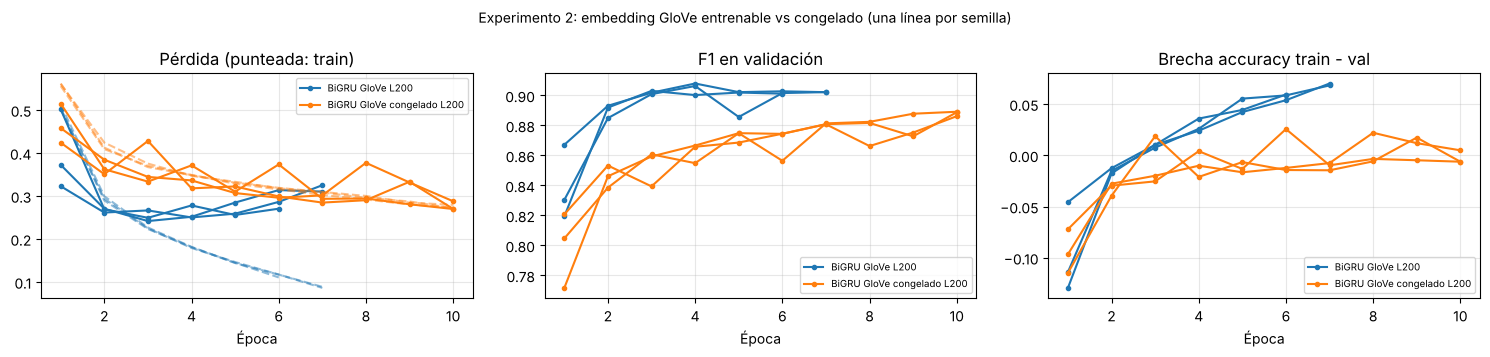

In [12]:
for seed in CONFIG["seeds"]:
    run_and_store(emb=BEST_EMB, seed=seed, freeze=True)

E2_TAGS = [tag_of(BEST_EMB, f, CONFIG["max_len"], s) for f in [False, True] for s in CONFIG["seeds"]]
e2 = tabla_exp(E2_TAGS)
display(e2.set_index("configuracion")[show_cols].round(4))
e2_ms = media_std(e2); display(e2_ms)
e2.to_csv(TAB / "exp2_congelar.csv", index=False); e2_ms.to_csv(TAB / "exp2_congelar_media_std.csv")
BEST_FREEZE = bool(e2.groupby("congelado").val_f1.mean().idxmax())
print(f"Embedding {'congelado' if BEST_FREEZE else 'entrenable'} elegido por F1 media de validación "
      f"({e2.groupby('congelado').val_f1.mean().round(4).to_dict()})")
gap = e2.assign(brecha=e2.train_acc - e2.val_acc).groupby("congelado").brecha.mean()
print("Brecha media de accuracy train - val en la mejor época:", gap.round(4).to_dict())
plot_runs(E2_TAGS, "exp2_curvas.png", f"Experimento 2: embedding {EMB_NAME[BEST_EMB]} entrenable vs congelado")

## 9. Configuración final de la red

La configuración final reúne el embedding ganador del experimento 1 y la opción (congelado o entrenable) ganadora del experimento 2, con 200 tokens y 3 semillas. No requiere entrenamiento adicional, porque sus corridas ya están entre las de los experimentos anteriores. Sobre ella se aplican el umbral, la calibración y los ensambles de la sección 10.

In [13]:
L_FIN = CONFIG["max_len"]
E3_TAGS = [tag_of(BEST_EMB, BEST_FREEZE, L_FIN, s) for s in CONFIG["seeds"]]
e3 = tabla_exp(E3_TAGS)
FINAL_NAME = e3.configuracion.iloc[0]
display(e3.set_index("configuracion")[show_cols].round(4))
e3_ms = media_std(e3); display(e3_ms)
e3.to_csv(TAB / "final_red.csv", index=False); e3_ms.to_csv(TAB / "final_red_media_std.csv")
print("Configuración final de la red:", FINAL_NAME)

,seed,parametros_entrenables,mejor_epoca,epocas,train_acc,val_acc,val_f1,test_precision,test_recall,test_f1,test_roc_auc,tiempo_min
configuracion,,,,,,,,,,,,
BiGRU GloVe L200,42,2064201,4,7,0.9308,0.9068,0.9079,0.9037,0.9082,0.9060,0.9652,35.8530
BiGRU GloVe L200,7,2064201,4,7,0.9303,0.9045,0.9062,0.8947,0.9163,0.9054,0.9639,34.5333
BiGRU GloVe L200,123,2064201,3,6,0.9107,0.9005,0.9030,0.8865,0.9156,0.9008,0.9629,28.6324


,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
configuracion,,,,,,
BiGRU GloVe L200,0.9057 ± 0.0025,0.9028 ± 0.0034,0.8950 ± 0.0086,0.9134 ± 0.0045,0.9040 ± 0.0028,0.9640 ± 0.0012


Configuración final de la red: BiGRU GloVe L200


## 10. Umbral, calibración y ensambles (ajustados en validación)

Ninguno de estos pasos requiere reentrenar: todos usan las probabilidades ya guardadas. Cada parámetro se elige en **validación** y luego se aplica una sola vez en **prueba**.

1. **Umbral ajustado.** Se elige el umbral *t* que maximiza la F1 de validación, buscando entre 0,05 y 0,95. Corrige el sesgo hacia una clase sin cambiar el ranking de las predicciones, así que el AUC no cambia.
2. **Calibración por temperatura** [13]. Los logits se dividen por un escalar *T* > 0 que minimiza la *log-loss* de validación. Las probabilidades se vuelven más honestas (menor ECE), mientras el ranking y las predicciones con umbral 0,5 se mantienen.
3. **Ensamble de semillas.** Se promedian las probabilidades de las 3 semillas de la configuración final. Reduce la varianza entre semillas.
4. **Ensamble RNN + TF-IDF.** Se usa P = *w*·P_RNN + (1 − *w*)·P_TF-IDF, con *w* elegido en validación por *log-loss*. Como los dos modelos solo comparten una parte de sus errores, combinarlos puede corregir errores de ambos. El umbral del ensamble también se ajusta en validación.

In [14]:
THR_GRID = np.round(np.arange(0.05, 0.951, 0.005), 3)

def best_threshold(y, p):
    f1s = [f1_score(y, p >= t) for t in THR_GRID]
    return float(THR_GRID[int(np.argmax(f1s))])

def fit_temperature(y, p):
    z = np.log(np.clip(p, 1e-7, 1 - 1e-7) / np.clip(1 - p, 1e-7, 1))
    nll = lambda T: log_loss(y, 1 / (1 + np.exp(-z / T)), labels=[0, 1])
    return float(minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x)

def apply_temperature(p, T):
    z = np.log(np.clip(p, 1e-7, 1 - 1e-7) / np.clip(1 - p, 1e-7, 1))
    return 1 / (1 + np.exp(-z / T))

def aligned(pred, ids):
    return pred.set_index("id").loc[ids, "prob"].values

VAL_IDS, TEST_IDS = VA.id.values, TE.id.values
y_val, y_test = VA.label.values, TE.label.values
bv, bt = aligned(base_val, VAL_IDS), aligned(base_test, TEST_IDS)

filas, sistemas, params = [], {}, {}
def registrar(nombre, semilla, pv, pt, thr=0.5, **extra):
    m = compute_metrics(y_test, pt, thr)
    filas.append(dict(sistema=nombre, semilla=semilla, umbral=thr, val_f1=f1_score(y_val, pv >= thr),
                      **{k: m[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "fp", "fn"]},
                      log_loss=log_loss(y_test, np.clip(pt, 1e-7, 1 - 1e-7), labels=[0, 1]), ece=ece(y_test, pt), **extra))
    sistemas.setdefault(nombre, {})[semilla] = (pv, pt, thr)

registrar("TF-IDF + RL", "-", bv, bt)
for tag in E3_TAGS:
    s = RESULTS[tag]["seed"]; pv, pt = aligned(PVAL[tag], VAL_IDS), aligned(PTEST[tag], TEST_IDS)
    registrar("RNN", s, pv, pt)
    registrar("RNN + umbral", s, pv, pt, best_threshold(y_val, pv))
    T = fit_temperature(y_val, pv)
    registrar("RNN + temperatura", s, apply_temperature(pv, T), apply_temperature(pt, T), T=T)
    W = np.round(np.arange(0, 1.001, 0.05), 2)
    w = float(W[int(np.argmin([log_loss(y_val, w_ * pv + (1 - w_) * bv, labels=[0, 1]) for w_ in W]))])
    ev, et = w * pv + (1 - w) * bv, w * pt + (1 - w) * bt
    registrar("RNN + TF-IDF", s, ev, et, w=w)
    registrar("RNN + TF-IDF + umbral", s, ev, et, best_threshold(y_val, ev), w=w)

# Ensambles sobre las 3 semillas (un solo sistema, sin desviación estándar)
pv3 = np.mean([aligned(PVAL[t], VAL_IDS) for t in E3_TAGS], axis=0); pt3 = np.mean([aligned(PTEST[t], TEST_IDS) for t in E3_TAGS], axis=0)
registrar("Ensamble de semillas", "3 sem.", pv3, pt3)
registrar("Ensamble de semillas + umbral", "3 sem.", pv3, pt3, best_threshold(y_val, pv3))
W = np.round(np.arange(0, 1.001, 0.05), 2)
w3 = float(W[int(np.argmin([log_loss(y_val, w_ * pv3 + (1 - w_) * bv, labels=[0, 1]) for w_ in W]))])
ev3, et3 = w3 * pv3 + (1 - w3) * bv, w3 * pt3 + (1 - w3) * bt
registrar("Ensamble de semillas + TF-IDF", "3 sem.", ev3, et3, w=w3)
registrar("Ensamble de semillas + TF-IDF + umbral", "3 sem.", ev3, et3, best_threshold(y_val, ev3), w=w3)

post = pd.DataFrame(filas)
post.to_csv(TAB / "postproceso_por_semilla.csv", index=False)
cols = ["val_f1", "accuracy", "precision", "recall", "f1", "roc_auc", "ece", "fp", "fn"]
g = post.groupby("sistema", sort=False)
res_post = g[cols].mean()
res_post.insert(0, "n", g.size())
res_post["f1_std"] = g.f1.std()
res_post["umbral"] = g.umbral.mean()
display(res_post.round(4))
res_post.to_csv(TAB / "postproceso_resumen.csv")
print("Parámetros elegidos en validación por semilla:")
display(post[post.sistema.isin(["RNN + umbral", "RNN + temperatura", "RNN + TF-IDF", "RNN + TF-IDF + umbral"])]
        [["sistema", "semilla", "umbral", "T", "w"]].round(3))

,n,val_f1,accuracy,precision,recall,f1,roc_auc,ece,fp,fn,f1_std,umbral
sistema,,,,,,,,,,,,
TF-IDF + RL,1,0.9136,0.9183,0.9161,0.9213,0.9187,0.9723,0.0374,252.0000,235.0000,NaN,0.500
RNN,3,0.9057,0.9028,0.8950,0.9134,0.9040,0.9640,0.0242,320.3333,258.6667,0.0028,0.500
RNN + umbral,3,0.9061,0.9031,0.8950,0.9142,0.9044,0.9640,0.0242,321.0000,256.3333,0.0029,0.500
RNN + temperatura,3,0.9057,0.9028,0.8950,0.9134,0.9040,0.9640,0.0092,320.3333,258.6667,0.0028,0.500
RNN + TF-IDF,3,0.9191,0.9207,0.9148,0.9283,0.9215,0.9742,0.0294,258.3333,214.0000,0.0011,0.500
RNN + TF-IDF + umbral,3,0.9199,0.9207,0.9158,0.9270,0.9213,0.9742,0.0294,254.6667,218.0000,0.0015,0.505
Ensamble de semillas,1,0.9082,0.9050,0.8975,0.9149,0.9061,0.9654,0.0205,312.0000,254.0000,NaN,0.500
Ensamble de semillas + umbral,1,0.9094,0.9035,0.8895,0.9220,0.9054,0.9654,0.0205,342.0000,233.0000,NaN,0.460
Ensamble de semillas + TF-IDF,1,0.9216,0.9228,0.9182,0.9287,0.9234,0.9743,0.0301,247.0000,213.0000,NaN,0.500


Parámetros elegidos en validación por semilla:


,sistema,semilla,umbral,T,w
2,RNN + umbral,42,0.500,NaN,NaN
3,RNN + temperatura,42,0.500,1.335,NaN
4,RNN + TF-IDF,42,0.500,NaN,0.5
5,RNN + TF-IDF + umbral,42,0.505,NaN,0.5
7,RNN + umbral,7,0.530,NaN,NaN
8,RNN + temperatura,7,0.500,1.352,NaN
9,RNN + TF-IDF,7,0.500,NaN,0.5
10,RNN + TF-IDF + umbral,7,0.525,NaN,0.5
12,RNN + umbral,123,0.470,NaN,NaN
13,RNN + temperatura,123,0.500,1.140,NaN


**Sistema final.** Entre los sistemas evaluados se elige el de mayor **F1 de validación** (columna `val_f1`). Así la selección final tampoco usa el conjunto de prueba. Los sistemas basados en una sola semilla se comparan por su media.

In [15]:
FINAL_SYS = res_post.val_f1.idxmax()
print(f"Sistema final por F1 de validación: '{FINAL_SYS}' (val F1 {res_post.loc[FINAL_SYS, 'val_f1']:.4f}, "
      f"test F1 {res_post.loc[FINAL_SYS, 'f1']:.4f})")
# Para gráficos y análisis de errores se usa la semilla 42 (o el ensamble de semillas si ese es el sistema final)
sem_rep = "3 sem." if "semillas" in FINAL_SYS else CONFIG["seeds"][0]
fv, ft, fthr = sistemas[FINAL_SYS][sem_rep]
rv, rt, _ = sistemas["RNN"][CONFIG["seeds"][0]]

Sistema final por F1 de validación: 'Ensamble de semillas + TF-IDF + umbral' (val F1 0.9223, test F1 0.9231)


## 11. Resultados cuantitativos en prueba

Primero se presenta la tabla comparativa con la versión 1, cuyas cifras se leen de `outputs/tables/resumen_test.csv`. Después vienen la matriz de confusión, las curvas ROC y de calibración, el IC 95 % por *bootstrap* de la diferencia con la línea base y el desempeño según la longitud de la reseña.

In [16]:
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
filas_t = []
V1_PATH = ROOT / "outputs/tables/resumen_test.csv"
if V1_PATH.exists() and not QUICK:
    v1 = pd.read_csv(V1_PATH, index_col=0)
    v1_l200 = "BiGRU W2V media+max L200 (semilla 42)"
    filas_t.append(dict(modelo="v1: " + v1_l200, **{c: v1.loc[v1_l200, c] for c in metric_cols}, f1_std=np.nan))
    v1_final = [i for i in v1.index if "media de" in str(i)][0]
    filas_t.append(dict(modelo="v1 final (referencia): " + v1_final.replace("media de 3 semillas", "3 semillas"),
                        **{c: v1.loc[v1_final, c] for c in metric_cols}, f1_std=v1.iloc[list(v1.index).index(v1_final) + 1]["f1"]))
filas_t.append(dict(modelo="TF-IDF (1-2 gramas) + regresión logística", **{c: base[f"test_{c}"] for c in metric_cols}, f1_std=np.nan))
for nombre_e, t in [("exp. 1", e1), ("exp. 2", e2[e2.congelado])]:
    for conf, gg in t.groupby("configuracion", sort=False):
        filas_t.append(dict(modelo=f"v2 {nombre_e}: {conf}, 3 semillas", **{c: gg[f"test_{c}"].mean() for c in metric_cols},
                            f1_std=gg.test_f1.std()))
for sname in ["RNN + umbral", "RNN + TF-IDF + umbral", "Ensamble de semillas + umbral", "Ensamble de semillas + TF-IDF + umbral"]:
    r = res_post.loc[sname]
    filas_t.append(dict(modelo=f"v2 final: {FINAL_NAME} → {sname}" + (" (3 semillas)" if r.n > 1 else ""),
                        **{c: r[c] for c in metric_cols}, f1_std=r.f1_std))
resumen = pd.DataFrame(filas_t).set_index("modelo")
display(resumen.round(4)); resumen.to_csv(TAB / "resumen_test_v2.csv")

print(f"\nReporte de clasificación del sistema final '{FINAL_SYS}' ({'ensamble' if sem_rep == '3 sem.' else 'semilla ' + str(sem_rep)}, umbral {fthr:.3f}):")
print(classification_report(y_test, (ft >= fthr).astype(int), target_names=["negativa", "positiva"], digits=4))

rng = np.random.default_rng(0); n = len(y_test); idxs = [rng.integers(0, n, n) for _ in range(1000)]
boot = [f1_score(y_test[i], ft[i] >= fthr) for i in idxs]
F1_CI = np.percentile(boot, [2.5, 97.5])
diff = [f1_score(y_test[i], ft[i] >= fthr) - f1_score(y_test[i], bt[i] >= 0.5) for i in idxs]
DIFF_CI = np.percentile(diff, [2.5, 97.5])
print(f"F1 del sistema final: {f1_score(y_test, ft >= fthr):.4f} (IC 95 % bootstrap: {F1_CI[0]:.4f} - {F1_CI[1]:.4f})")
print(f"Diferencia de F1 (sistema final - línea base): {np.mean(diff):+.4f} (IC 95 %: {DIFF_CI[0]:+.4f} a {DIFF_CI[1]:+.4f})")

,accuracy,precision,recall,f1,roc_auc,f1_std
modelo,,,,,,
v1: BiGRU W2V media+max L200 (semilla 42),0.9020,0.8945,0.9119,0.9032,0.9631,NaN
"v1 final (referencia): BiGRU W2V media+max L400, 3 semillas",0.9107,0.9018,0.9226,0.9119,0.9687,0.0034
TF-IDF (1-2 gramas) + regresión logística,0.9183,0.9161,0.9213,0.9187,0.9723,NaN
"v2 exp. 1: BiGRU Word2Vec L200, 3 semillas",0.9025,0.8891,0.9202,0.9044,0.9633,0.0010
"v2 exp. 1: BiGRU GloVe L200, 3 semillas",0.9028,0.8950,0.9134,0.9040,0.9640,0.0028
"v2 exp. 2: BiGRU GloVe congelado L200, 3 semillas",0.8888,0.8791,0.9035,0.8907,0.9576,0.0014
v2 final: BiGRU GloVe L200 → RNN + umbral (3 semillas),0.9031,0.8950,0.9142,0.9044,0.9640,0.0029
v2 final: BiGRU GloVe L200 → RNN + TF-IDF + umbral (3 semillas),0.9207,0.9158,0.9270,0.9213,0.9742,0.0015
v2 final: BiGRU GloVe L200 → Ensamble de semillas + umbral,0.9035,0.8895,0.9220,0.9054,0.9654,NaN



Reporte de clasificación del sistema final 'Ensamble de semillas + TF-IDF + umbral' (ensamble, umbral 0.510):
              precision    recall  f1-score   support

    negativa     0.9257    0.9186    0.9221      2972
    positiva     0.9196    0.9267    0.9231      2986

    accuracy                         0.9226      5958
   macro avg     0.9227    0.9226    0.9226      5958
weighted avg     0.9226    0.9226    0.9226      5958



F1 del sistema final: 0.9231 (IC 95 % bootstrap: 0.9160 - 0.9299)
Diferencia de F1 (sistema final - línea base): +0.0044 (IC 95 %: -0.0012 a +0.0100)


,n,acc_rnn_s42,acc_base,acc_final
≤100,727.0,0.9147,0.9243,0.9354
101-200,2766.0,0.9071,0.9132,0.9172
201-400,1708.0,0.9046,0.9210,0.9204
>400,757.0,0.8930,0.9247,0.9353


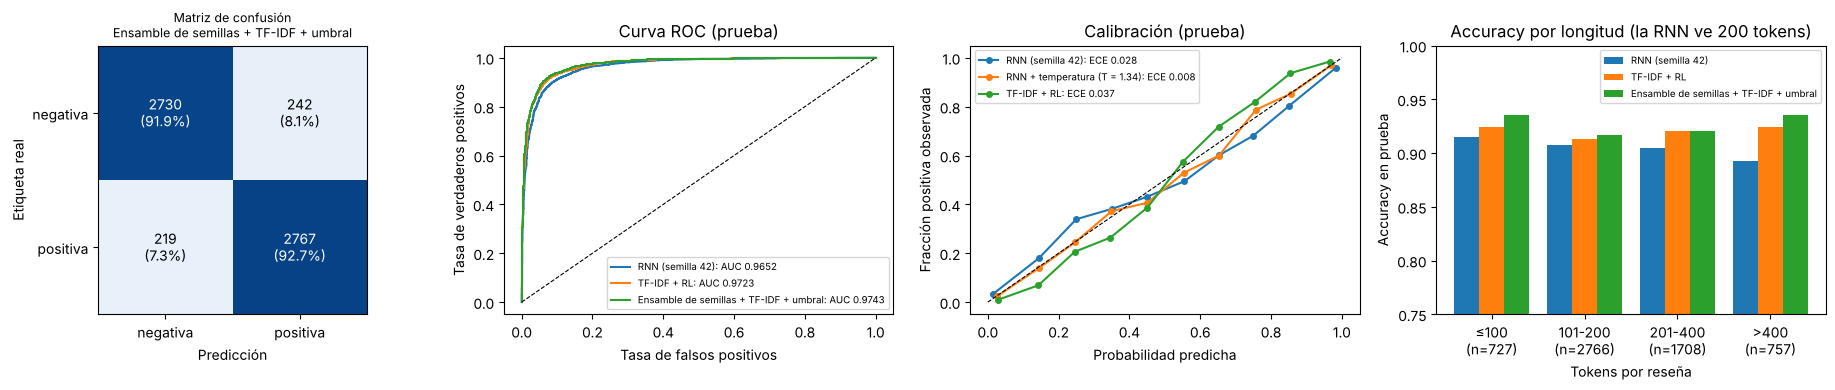

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
cm = confusion_matrix(y_test, (ft >= fthr).astype(int))
ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                   color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
ax[0].set_xticks([0, 1], ["negativa", "positiva"]); ax[0].set_yticks([0, 1], ["negativa", "positiva"])
ax[0].set_xlabel("Predicción"); ax[0].set_ylabel("Etiqueta real"); ax[0].set_title(f"Matriz de confusión\n{FINAL_SYS}", fontsize=9)

curvas = [("RNN (semilla 42)", rt), ("TF-IDF + RL", bt), (FINAL_SYS, ft)]
for name, p in curvas:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[1].plot(fpr, tpr, label=f"{name}: AUC {roc_auc_score(y_test, p):.4f}")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curva ROC (prueba)"); ax[1].legend(fontsize=7)

# Diagrama de confiabilidad: probabilidad predicha vs frecuencia observada de la clase positiva
T42 = float(post.loc[(post.sistema == "RNN + temperatura") & (post.semilla == CONFIG["seeds"][0]), "T"].iloc[0])
for name, p in [("RNN (semilla 42)", rt), (f"RNN + temperatura (T = {T42:.2f})", apply_temperature(rt, T42)), ("TF-IDF + RL", bt)]:
    edges = np.linspace(0, 1, 11); b = np.clip(np.digitize(p, edges) - 1, 0, 9)
    xs = [p[b == k].mean() for k in range(10) if (b == k).sum() > 20]; ys = [y_test[b == k].mean() for k in range(10) if (b == k).sum() > 20]
    ax[2].plot(xs, ys, marker="o", ms=4, label=f"{name}: ECE {ece(y_test, p):.3f}")
ax[2].plot([0, 1], [0, 1], "k--", lw=0.8); ax[2].set_xlabel("Probabilidad predicha"); ax[2].set_ylabel("Fracción positiva observada")
ax[2].set_title("Calibración (prueba)"); ax[2].legend(fontsize=7)

bins = [0, 100, 200, 400, 10_000]; labels = ["≤100", "101-200", "201-400", ">400"]
B = pd.DataFrame({"n_tokens": TE.set_index("id").loc[TEST_IDS, "n_tokens"].values, "y": y_test,
                  "rnn": rt >= 0.5, "base": bt >= 0.5, "final": ft >= fthr})
B["tramo"] = pd.cut(B.n_tokens, bins=bins, labels=labels)
por_long = pd.DataFrame({t: {"n": len(g_), "acc_rnn_s42": accuracy_score(g_.y, g_.rnn), "acc_base": accuracy_score(g_.y, g_.base),
                             "acc_final": accuracy_score(g_.y, g_.final)}
                         for t, g_ in B.groupby("tramo", observed=True)}).T
display(por_long.round(4)); por_long.to_csv(TAB / "desempeno_por_longitud.csv")
xx = np.arange(len(por_long))
for k, (col, lab) in enumerate([("acc_rnn_s42", "RNN (semilla 42)"), ("acc_base", "TF-IDF + RL"), ("acc_final", FINAL_SYS)]):
    ax[3].bar(xx + (k - 1) * 0.27, por_long[col], 0.27, label=lab)
ax[3].set_xticks(xx, [f"{t}\n(n={int(n_)})" for t, n_ in zip(por_long.index, por_long.n)])
ax[3].set_ylim(0.75, 1.0); ax[3].set_xlabel("Tokens por reseña"); ax[3].set_ylabel("Accuracy en prueba")
ax[3].set_title(f"Accuracy por longitud (la RNN ve {L_FIN} tokens)"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "resultados_cuantitativos.png", dpi=150); plt.show()

## 12. Resultados cualitativos

Se muestran ejemplos de prueba del sistema final: aciertos con alta confianza de cada clase y los errores con mayor confianza. Además, se identifican las reseñas que la RNN sola (semilla 42, umbral 0,5) clasificaba mal y que el sistema final **corrige**, y las que el sistema final **empeora**.

In [18]:
Q = TE.set_index("id").loc[TEST_IDS, ["text", "n_tokens"]].reset_index()
Q["y"], Q["p_rnn"], Q["p_base"], Q["p_final"] = y_test, rt, bt, ft
Q["pred"] = (Q.p_final >= fthr).astype(int)
Q["confianza"] = np.where(Q.pred == 1, Q.p_final, 1 - Q.p_final)
Q["visto"] = Q.text.map(lambda t: " ".join(truncate(tokenize(t), CONFIG["truncado"], L_FIN)))
nombre = {0: "negativa", 1: "positiva"}
err_rnn, err_fin = (Q.p_rnn >= 0.5).astype(int) != Q.y, Q.pred != Q.y
sel = pd.concat([
    Q[(Q.y == 1) & (Q.pred == 1)].nlargest(2, "confianza").assign(caso="acierto"),
    Q[(Q.y == 0) & (Q.pred == 0)].nlargest(2, "confianza").assign(caso="acierto"),
    Q[(Q.y == 0) & (Q.pred == 1)].nlargest(2, "confianza").assign(caso="falso positivo"),
    Q[(Q.y == 1) & (Q.pred == 0)].nlargest(2, "confianza").assign(caso="falso negativo"),
    Q[err_rnn & ~err_fin].assign(d=lambda d: (d.p_final - d.p_rnn).abs()).nlargest(3, "d").assign(caso="corregido por el sistema final"),
])
cual = pd.DataFrame({"caso": sel.caso, "real": sel.y.map(nombre), "predicha": sel.pred.map(nombre),
                     "P_RNN": sel.p_rnn.round(3), "P_TF-IDF": sel.p_base.round(3), "P_final": sel.p_final.round(3),
                     "tokens": sel.n_tokens, "fragmento leído por la RNN": sel.visto.str.slice(0, 380) + " ..."})
cual.to_csv(TAB / "ejemplos_cualitativos.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(cual)

print(f"Errores RNN (semilla 42, umbral 0,5): {int(err_rnn.sum())} | sistema final: {int(err_fin.sum())} | "
      f"corregidos: {int((err_rnn & ~err_fin).sum())} | nuevos: {int((~err_rnn & err_fin).sum())}")
print(f"Falsos positivos / negativos del sistema final: {int(((Q.y == 0) & (Q.pred == 1)).sum())} / {int(((Q.y == 1) & (Q.pred == 0)).sum())}")
print(f"Errores del sistema final con confianza > 0,9: {int((Q.confianza[err_fin] > 0.9).sum())} "
      f"(RNN semilla 42: {int((np.maximum(Q.p_rnn, 1 - Q.p_rnn)[err_rnn] > 0.9).sum())})")

,caso,real,predicha,P_RNN,P_TF-IDF,P_final,tokens,fragmento leído por la RNN
965,acierto,positiva,positiva,1.000,1.000,1.000,54,this movie was incredible i would recommend it to anyone much better than what i had already anticipated it was definitely a heart wrenching spectacular movie it is an amazing story with amazing actors and creators definitely another great movie with denzel washington shouldn't surprise anyone derek luke did a wonderful job as well ...
5856,acierto,positiva,positiva,1.000,0.999,1.000,137,certainly one of the finest movies i have seen for quite some time exquisite direction and flawless acting make this a very entertaining and often moving film denzel washington plays one of his most engaging and emotional roles to date and the rest of the cast perform beautifully christopher walken is of course superb in his part although he did not appear as often as i would h ...
2106,acierto,negativa,negativa,0.000,0.000,0.000,110,for shame for shame that a fine actor such as joseph fiennes would allow himself to be cast in this piece of nauseating drivel the movie was not only bad but down right horrible and of no redeeming quality the plot was there one ? seemed to go no where the russians played silly kill or be killed games and the rest of the cast should be declared null and void for their pathetic ...
3557,acierto,negativa,negativa,0.000,0.000,0.000,138,this is the worst movie i have ever seen if i wasn't watching it for free i would have never finished it the creators of this film should be ashamed of themselves it seems like this is supposed to be a film in the vein of scary movie and date movie a terrible movie but 10x better than this one but failed miserably the only jokes in this movie seem to be based on slapstick a guy ...
2114,falso positivo,negativa,positiva,0.999,0.998,0.999,82,this movie was pure genius john waters is brilliant it is hilarious and i am not sick of it even after seeing it about 20 times since i bought it a few months ago the acting is great although ricki lake could have been better and johnny depp is magnificent he is such a beautiful man and a very talented actor and seeing most of johnny's movies this is probably my favorite i give ...
3569,falso positivo,negativa,positiva,0.999,0.992,0.995,126,this sleek sexy movie is a must see only upon multiple viewings can one truly understand the uniqueness of this film personally i enjoy the narrator for his intelligent no subject left untouched style of narration the introduction grips you right away and holds you at the edge of your seat throughout the film he provides wonderful insight into the world of the trainables and al ...
5439,falso negativo,positiva,negativa,0.001,0.003,0.002,116,this movie has everything that makes a bad movie worth watching sloppy editing little to no continuity insane dialog bad you might even say non existent acting pointless story lines shots that go on far too long and it's perfect for mst3k style riffing not to mention the corpse eaters drinking game scribble on forms take a shot sign your name take a shot catch a bad foley edit ...
1754,falso negativo,positiva,negativa,0.002,0.004,0.003,107,this flick is sterling example of the state of erotic b movies bad porn movies without the hardcore sex the plot in this one isn't so bad as these things go it involves a female lawyer trying to prove her lover is innocent of killing his wife the rest of the movie however leaves something to be desired bad acting bad direction bad looking woman bad sets bad cinematography bad s ...
2826,corregido por el sistema final,positiva,positiva,0.186,0.929,0.646,690,there have been far too few mainstream films set in post colonial africa and the ones that have are a mixed bunch this one with its altruistic pretensions to expose slavery in the 1970s shows the best and worst values of africa which turn out not to be too different to carry on with the bargaining without considering the consequences the scene where the two men hag

Errores RNN (semilla 42, umbral 0,5): 563 | sistema final: 461 | corregidos: 157 | nuevos: 55
Falsos positivos / negativos del sistema final: 242 / 219
Errores del sistema final con confianza > 0,9: 54 (RNN semilla 42: 177)


## 13. Figuras y cifras para el informe

Las figuras del informe (Fig. 1 y Fig. 2 del paper) se exportan a `report/figs/` y las cifras citadas a `outputs/tables/v2/resumen_informe.json`, para que el informe y el notebook coincidan.

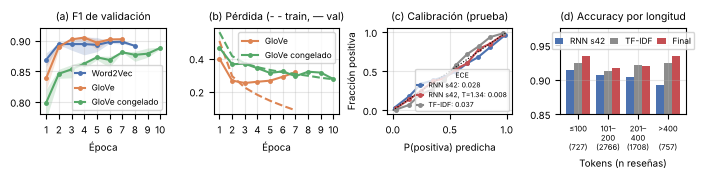

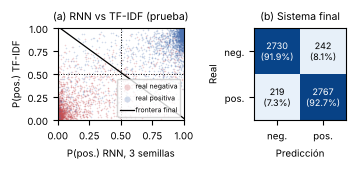

Reseñas de prueba donde RNN (3 semillas) y TF-IDF discrepan: 469 (7.9%)


In [19]:
# Figuras del informe (formato IEEE: 7,0 in a doble columna y 3,4 in a una columna)
plt.rcParams.update({"font.size": 7, "axes.titlesize": 7.5, "legend.fontsize": 6, "axes.labelsize": 7})
C_W2V, C_GLOVE, C_FROZ = "#4C72B0", "#DD8452", "#55A868"
C_RNN, C_BASE, C_FIN = "#4C72B0", "#8C8C8C", "#C44E52"

# Figura 1: (a) F1 de validación por época, (b) pérdidas train/val, (c) calibración, (d) accuracy por longitud
fig, ax = plt.subplots(1, 4, figsize=(7.0, 1.65))
grupos = [(E1_TAGS[:len(CONFIG["seeds"])], "Word2Vec", C_W2V), (E1_TAGS[len(CONFIG["seeds"]):], "GloVe", C_GLOVE),
          ([t for t in E2_TAGS if RESULTS[t]["congelado"]], "GloVe congelado", C_FROZ)]
for tags, lab, c in grupos:
    H = pd.concat([HIST[t] for t in tags]).groupby("epoch")
    m = H.val_f1.mean()
    ax[0].plot(m.index, m, marker="o", ms=2.5, color=c, label=lab)
    ax[0].fill_between(m.index, H.val_f1.min(), H.val_f1.max(), color=c, alpha=0.2, lw=0)
    if lab != "Word2Vec":
        ax[1].plot(m.index, H.train_loss.mean(), ls="--", color=c)
        ax[1].plot(m.index, H.val_loss.mean(), marker="o", ms=2.5, color=c, label=lab)
ax[0].set_title("(a) F1 de validación"); ax[0].set_xlabel("Época"); ax[0].set_ylim(0.78, 0.92); ax[0].legend(loc="lower right", handlelength=1.2)
ax[1].set_title("(b) Pérdida (- - train, — val)"); ax[1].set_xlabel("Época"); ax[1].legend(loc="upper right")
T42 = float(post.loc[(post.sistema == "RNN + temperatura") & (post.semilla == CONFIG["seeds"][0]), "T"].iloc[0])
for name, p, c in [("RNN s42", rt, C_RNN), (f"RNN s42, T={T42:.2f}", apply_temperature(rt, T42), C_FIN), ("TF-IDF", bt, C_BASE)]:
    edges = np.linspace(0, 1, 11); bb = np.clip(np.digitize(p, edges) - 1, 0, 9)
    ks = [k for k in range(10) if (bb == k).sum() > 20]
    ax[2].plot([p[bb == k].mean() for k in ks], [y_test[bb == k].mean() for k in ks], marker="o", ms=2.5, color=c,
               label=f"{name}: {ece(y_test, p):.3f}")
ax[2].plot([0, 1], [0, 1], "k:", lw=0.8); ax[2].set_title("(c) Calibración (prueba)")
ax[2].set_xlabel("P(positiva) predicha"); ax[2].set_ylabel("Fracción positiva"); ax[2].legend(loc="lower right", handlelength=0.8, fontsize=5, title="ECE", title_fontsize=5, borderpad=0.3, labelspacing=0.2)
for k, (col, lab, c) in enumerate([("acc_rnn_s42", "RNN s42", C_RNN), ("acc_base", "TF-IDF", C_BASE), ("acc_final", "Final", C_FIN)]):
    ax[3].bar(xx + (k - 1) * 0.27, por_long[col], 0.27, label=lab, color=c)
ax[3].set_xticks(xx, [f"{t}\n({int(n_)})".replace("-", "–\n") if "-" in t else f"{t}\n\n({int(n_)})" for t, n_ in zip(por_long.index, por_long.n)], fontsize=5.5)
ax[3].set_ylim(0.85, 0.975); ax[3].set_title("(d) Accuracy por longitud"); ax[3].set_xlabel("Tokens (n reseñas)")
ax[3].legend(loc="upper center", ncol=3, columnspacing=0.6, handlelength=1)
from matplotlib.ticker import MaxNLocator
for a_ in ax:
    a_.grid(alpha=0.3)
for a_ in ax[:2]:
    a_.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(pad=0.3, w_pad=0.6); plt.savefig(REPORT_FIGS / "fig1_entrenamiento_calibracion_longitud.pdf", bbox_inches="tight"); plt.show()

# Figura 2: (a) P_RNN (3 semillas) vs P_TF-IDF con las fronteras de decisión, (b) matriz de confusión del sistema final
fig, ax = plt.subplots(1, 2, figsize=(3.45, 1.55), gridspec_kw={"width_ratios": [1.15, 1]})
for lab, c, nm in [(0, C_FIN, "negativa"), (1, C_RNN, "positiva")]:
    m = y_test == lab
    ax[0].scatter(pt3[m], bt[m], s=1.2, alpha=0.25, color=c, label=f"real {nm}", rasterized=True, lw=0)
xs = np.linspace(0, 1, 50)
ax[0].plot(xs, (fthr - w3 * xs) / (1 - w3), "k-", lw=0.9, label="frontera final")
ax[0].axvline(0.5, color="k", ls=":", lw=0.7); ax[0].axhline(0.5, color="k", ls=":", lw=0.7)
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1); ax[0].set_xlabel("P(pos.) RNN, 3 semillas"); ax[0].set_ylabel("P(pos.) TF-IDF")
ax[0].set_title("(a) RNN vs TF-IDF (prueba)"); ax[0].legend(loc="lower right", markerscale=4, fontsize=5, handletextpad=0.2)
ax[1].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center", fontsize=6.5,
                   color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
ax[1].set_xticks([0, 1], ["neg.", "pos."]); ax[1].set_yticks([0, 1], ["neg.", "pos."])
ax[1].set_xlabel("Predicción"); ax[1].set_ylabel("Real"); ax[1].set_title("(b) Sistema final")
plt.tight_layout(pad=0.3, w_pad=0.5); plt.savefig(REPORT_FIGS / "fig2_rnn_vs_tfidf_confusion.pdf", bbox_inches="tight", dpi=300); plt.show()
plt.rcParams.update(plt.rcParamsDefault)

# Cifras adicionales citadas en el informe
DESACUERDO = int(((pt3 >= 0.5) != (bt >= 0.5)).sum())
print(f"Reseñas de prueba donde RNN (3 semillas) y TF-IDF discrepan: {DESACUERDO} ({DESACUERDO / len(y_test):.1%})")

In [20]:
def ms(t, col):
    return f"{t[col].mean():.4f} ± {t[col].std():.4f}"
resumen_informe = {
    "versiones": VERSIONS, "dispositivo": str(DEVICE), "modo_rapido": QUICK,
    "dataset": {"únicas": int(len(raw) - dup_mask.sum()), "partición": tabla.total.to_dict(), "vocabulario": V},
    "glove": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in glove_stats.items()},
    "linea_base": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in base.items()},
    "experimento_1": {c: {"val_f1": ms(gg, "val_f1"), "test_f1": ms(gg, "test_f1"), "mejor_epoca": gg.mejor_epoca.tolist(),
                          "tiempo_min": round(gg.tiempo_min.mean(), 1)} for c, gg in e1.groupby("configuracion")},
    "mejor_embedding": BEST_EMB,
    "experimento_2": {c: {"val_f1": ms(gg, "val_f1"), "test_f1": ms(gg, "test_f1"), "brecha_train_val": round(float((gg.train_acc - gg.val_acc).mean()), 4),
                          "parametros_entrenables": int(gg.parametros_entrenables.iloc[0]), "tiempo_min": round(gg.tiempo_min.mean(), 1)}
                      for c, gg in e2.groupby("configuracion")},
    "congelar_elegido": BEST_FREEZE,
    "red_final": {"configuracion": FINAL_NAME, **{m: ms(e3, f"test_{m}") for m in metric_cols}, "val_f1": ms(e3, "val_f1"),
                      "tiempo_min": [round(v, 1) for v in e3.tiempo_min]},
    "postproceso": res_post.round(4).reset_index().to_dict(orient="records"),
    "sistema_final": FINAL_SYS,
    "sistema_final_f1_ic95": [round(float(v), 4) for v in F1_CI],
    "diferencia_vs_linea_base_ic95": [round(float(np.mean(diff)), 4)] + [round(float(v), 4) for v in DIFF_CI],
    "accuracy_por_longitud": por_long.round(4).to_dict(orient="index"),
    "desacuerdo_rnn_tfidf": DESACUERDO,
    "errores": {"rnn_s42": int(err_rnn.sum()), "final": int(err_fin.sum()), "corregidos": int((err_rnn & ~err_fin).sum()),
                "nuevos": int((~err_rnn & err_fin).sum()), "fp_final": int(cm[0, 1]), "fn_final": int(cm[1, 0])},
}
(TAB / "resumen_informe.json").write_text(json.dumps(resumen_informe, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(resumen_informe, indent=1, ensure_ascii=False, default=str))

{
 "versiones": {
  "python": "3.13.18",
  "torch": "2.15.0+cu132",
  "gensim": "4.4.0",
  "numpy": "2.5.3",
  "pandas": "3.0.5",
  "scikit-learn": "1.9.1"
 },
 "dispositivo": "cpu",
 "modo_rapido": false,
 "dataset": {
  "únicas": 39720,
  "partición": {
   "train": 27804,
   "val": 5958,
   "test": 5958
  },
  "vocabulario": 20002
 },
 "glove": {
  "palabras_glove": 400000,
  "cobertura_directa": 0.9665,
  "cobertura_con_contracciones": 0.996,
  "contracciones_resueltas": 592
 },
 "linea_base": {
  "modelo": "TF-IDF (1-2 gramas) + regresión logística",
  "C": 8.0,
  "val_f1": 0.9136,
  "test_accuracy": 0.9183,
  "test_precision": 0.9161,
  "test_recall": 0.9213,
  "test_f1": 0.9187,
  "test_f1_macro": 0.9183,
  "test_roc_auc": 0.9723,
  "test_tn": 2720.0,
  "test_fp": 252.0,
  "test_fn": 235.0,
  "test_tp": 2751.0
 },
 "experimento_1": {
  "BiGRU GloVe L200": {
   "val_f1": "0.9057 ± 0.0025",
   "test_f1": "0.9040 ± 0.0028",
   "mejor_epoca": [
    4,
    4,
    3
   ],
   "tiempo_mi

## 14. Resultados y discusión

*Escrito a partir de las salidas de este notebook. Todo se ejecutó en CPU de 2 núcleos. Cada corrida con 200 tokens tomó entre 20 y 46 min. La variación se debe a que el contenedor se reinició dos veces durante el entrenamiento y quedó en máquinas de distinta velocidad (unos 290 s y unos 120 s por época). Dos corridas (`word2vec_s42` y `glove-congelado_s7`) se reanudaron desde su checkpoint de la época 2.*

### 14.1 Resultados cuantitativos

**Tabla I.** Resultados en prueba (5 958 reseñas). Precision, recall y F1 de la clase positiva. "3 sem." indica media ± desviación estándar de 3 semillas.

| Modelo | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| v1: BiGRU, Word2Vec, media+máx, 200 tokens (semilla 42) | 0,9020 | 0,8945 | 0,9119 | 0,9032 | 0,9631 |
| v1 final: BiGRU, Word2Vec, media+máx, 400 tokens (3 sem.) | 0,9107 | 0,9018 | 0,9226 | 0,9119 ± 0,0034 | 0,9687 |
| TF-IDF (1-2 gramas) + regresión logística | 0,9183 | 0,9161 | 0,9213 | 0,9187 | 0,9723 |
| v2 exp. 1: BiGRU, Word2Vec, 200 tokens (3 sem.) | 0,9025 | 0,8891 | 0,9202 | 0,9044 ± 0,0010 | 0,9633 |
| v2 exp. 1: BiGRU, GloVe, 200 tokens (3 sem.) | 0,9028 | 0,8950 | 0,9134 | 0,9040 ± 0,0028 | 0,9640 |
| v2 exp. 2: BiGRU, GloVe congelado, 200 tokens (3 sem.) | 0,8888 | 0,8791 | 0,9035 | 0,8907 ± 0,0014 | 0,9576 |
| v2: RNN (GloVe) + TF-IDF, peso elegido en validación (3 sem.) | 0,9207 | 0,9148 | 0,9283 | 0,9215 ± 0,0011 | 0,9742 |
| **v2 final: ensamble de 3 semillas + TF-IDF + umbral** | **0,9226** | **0,9196** | **0,9267** | **0,9231** | **0,9743** |

El sistema final, elegido por F1 de validación (0,9223), obtiene en prueba F1 = 0,9231 (IC 95 % por *bootstrap*: 0,9160 a 0,9299). Sus errores están equilibrados entre las clases: 242 falsos positivos y 219 falsos negativos, con recall de 0,919 en negativas y 0,927 en positivas.

### 14.2 Análisis

**Reproducibilidad respecto a la versión 1.** Con la misma partición, la línea base TF-IDF reproduce exactamente las cifras de la versión 1 (F1 de validación 0,9136 y de prueba 0,9187). La BiGRU con Word2Vec, media + máximo y 200 tokens (semilla 42) obtiene F1 de prueba 0,9048, frente a 0,9032 en la versión 1. La diferencia es menor que la variación entre semillas (± 0,0010), aunque la matriz Word2Vec no es idéntica: ahora se entrena con un hilo y *hash* fijo.

**Word2Vec frente a GloVe (experimento 1).** GloVe gana en F1 media de validación (0,9057 ± 0,0025 frente a 0,9036 ± 0,0029), por lo que el protocolo lo elige. Sin embargo, la diferencia (0,002) es menor que una desviación estándar, y en prueba los dos quedan empatados (0,9040 ± 0,0028 frente a 0,9044 ± 0,0010). **La fuente de los embeddings preentrenados no cambia el resultado.** La gran ganancia de la versión 1 (+2 a +3 puntos de F1) venía de inicializar con *algún* conocimiento previo en lugar de vectores aleatorios, no de la calidad de ese conocimiento. Dos factores lo explican:
1. El embedding se ajusta durante el entrenamiento: sus 2 M de parámetros se adaptan a la tarea y diluyen la diferencia de partida. GloVe empieza peor en la primera época, con F1 de validación de unos 0,84 frente a unos 0,87 de Word2Vec, y lo alcanza hacia la época 3 (figura del experimento 1).
2. GloVe aprende de co-ocurrencias generales, no de polaridad. Sus vecinos de *boring* incluyen *funny* y los de *excellent* incluyen *good*, mientras que Word2Vec, entrenado con reseñas, agrupa mejor por sentimiento (*boring* → *dull*, *pointless*, *tedious*) (sección 3). Esto ya se había observado en la literatura de vectores para sentimiento [4].

Como el *tokenizador* conserva las contracciones, resolverlas por partes (`didn't` → `did` + `n't`) subió la cobertura de GloVe del 96,6 % al 99,6 % del vocabulario (592 palabras). Sin esto, las negaciones habrían quedado con vectores aleatorios.

**Embedding congelado (experimento 2).** Congelar GloVe reduce los parámetros entrenables de 2,06 M a 64 k y elimina el sobreajuste: la brecha de accuracy train − val en la mejor época pasa de +0,020 a −0,003 y la pérdida de validación ya no sube (figura del experimento 2). Aun así, el desempeño cae 1,3 puntos de F1 en prueba (0,8907 frente a 0,9040). Es un caso de **subajuste**: el modelo congelado seguía mejorando al llegar al tope de 10 épocas (las 3 semillas tuvieron su mejor época en la 10). Además, sin ajustar los vectores la red no puede separar palabras que GloVe deja cerca pese a tener polaridad opuesta. En este problema, adaptar el embedding aporta más de lo que cuesta su sobreajuste, y el *early stopping* sobre la F1 de validación basta para controlarlo.

**Umbral (sección 10).** Los umbrales elegidos en validación quedaron entre 0,47 y 0,53 y cambiaron la F1 de prueba en +0,0004 en promedio, un efecto despreciable. El sesgo hacia falsos positivos de la versión 1 (375 frente a 175) era propio de esa corrida (400 tokens, semilla 42). Con GloVe y 200 tokens el reparto es más parejo (320 frente a 259 en promedio), así que el umbral de 0,5 ya era adecuado.

**Calibración.** La temperatura óptima fue *T* = 1,14 a 1,35 en las tres semillas. Un valor de *T* > 1 confirma que la red es **sobreconfiada**: sus probabilidades son más extremas de lo que justifica su tasa de acierto. Dividir los logits por *T* reduce el ECE de prueba de 0,024 a 0,009 sin cambiar las predicciones ni la F1 (diagrama de confiabilidad de la sección 11). Esto vale cuando las probabilidades se usan para algo más que decidir la clase, por ejemplo para priorizar reseñas dudosas.

**Ensambles.** Promediar las 3 semillas sube la F1 de 0,9040 (media) a 0,9061. La mejora grande viene de **combinar la RNN con TF-IDF**: con *w* ≈ 0,4 a 0,5 elegido en validación, la F1 de prueba pasa a 0,9215 ± 0,0011, y las tres semillas superan por separado a la línea base (0,9187) y al modelo final de la versión 1 (0,9119). Los dos modelos se complementan:
- La RNN modela el orden y las negaciones, pero solo lee 200 tokens.
- TF-IDF ve la reseña completa, pero ignora el orden más allá de los bigramas.

El gráfico por longitud lo muestra. En reseñas de más de 400 tokens, la RNN sola acierta 0,893, TF-IDF 0,925 y el sistema final 0,935: la línea base compensa el truncamiento. El sistema final corrige 157 de los 563 errores de la RNN (semilla 42) e introduce 55 nuevos. Los errores con confianza mayor a 0,9 bajan de 177 a 54.

**Comparación con la línea base.** El sistema final supera a TF-IDF en 0,44 puntos de F1. El IC 95 % de la diferencia (−0,0012 a +0,0100) **incluye el cero**, de modo que la mejora no es estadísticamente concluyente con 5 958 reseñas de prueba. Lo que sí es claro es que la RNN aporta información que la línea base no tiene: el ensamble mejora a la RNN sola en 1,9 puntos y a TF-IDF en todas las semillas. Por otro lado, la versión de umbral 0,5 (F1 0,9234) es apenas mejor en prueba, pero no se eligió porque su F1 de validación era menor. Se respetó la regla de seleccionar solo con validación.

**Análisis cualitativo (sección 12).** Los errores de mayor confianza son los mismos tipos que en la versión 1, y ningún modelo de esta versión los resuelve:
1. **Posible ruido de etiquetado:** *this movie was pure genius*, etiquetada como negativa, recibe P(positiva) = 0,999 en la RNN, en TF-IDF y en el sistema final.
2. **Ironía:** *everything that makes a bad movie worth watching* es una reseña positiva escrita con vocabulario negativo.

Los casos corregidos muestran el mecanismo del ensamble. Una reseña positiva de 690 tokens, de la que la RNN solo lee 200, pasa de P = 0,19 a 0,65 gracias a TF-IDF (0,93). Una crítica negativa de un *remake*, escrita con un tono elogioso hacia el original, pasa de 0,91 (RNN) a 0,45.

### 14.3 Limitaciones
- **Longitud de 200 tokens.** Se eligió por el cómputo disponible. La RNN sola de la versión 2 (0,9040) queda por debajo de la RNN final de la versión 1 con 400 tokens (0,9119). No se probó la combinación de GloVe, 400 tokens y ensamble con TF-IDF, que probablemente sería la mejor.
- **Modelo congelado sin converger.** Quedó limitado por el tope de 10 épocas. Con más épocas, o descongelando después de unas épocas, la brecha con el modelo entrenable podría reducirse.
- **El sistema final no es una RNN pura.** Incluye un modelo lineal. La RNN cumple por sí sola el enunciado (sección 9), y el ensamble es una mejora adicional que se reporta por separado.
- **Pocas semillas.** Tres semillas detectan diferencias de alrededor de 1 punto, pero no de 0,2 (Word2Vec frente a GloVe, umbral).
- **Reanudaciones.** Dos corridas se reanudaron desde un checkpoint tras reinicios del contenedor. Al reanudar, el estado aleatorio se re-siembra, así que no son idénticas bit a bit a una corrida continua.
- **Etiquetas ruidosas** fijan un techo al desempeño medible (sección 12).

### 14.4 Mejoras propuestas
1. Entrenar la configuración GloVe + media/máx con **400 tokens y 3 semillas** (unas 2 h por corrida en CPU, mucho menos en GPU) y repetir los ensambles sobre ella.
2. **Descongelado gradual:** entrenar unas épocas con el embedding congelado y luego ajustarlo con una tasa de aprendizaje menor, para combinar la estabilidad del modelo congelado con la adaptación del entrenable.
3. **Lectura completa de reseñas largas** (segmentos de 200 tokens con promedio de predicciones, o atención), en lugar de depender de TF-IDF para esa parte.
4. **Apilamiento** (*stacking*) con validación cruzada en lugar de un peso fijo, si se dispone de más datos de validación.

### 14.5 Conclusiones
- Con la misma partición, la versión 2 reproduce los resultados de la versión 1 (línea base idéntica; RNN con Word2Vec dentro del ruido entre semillas).
- Word2Vec entrenado en el dominio y GloVe preentrenado rinden igual una vez que el embedding se ajusta. Congelarlo elimina el sobreajuste, pero cuesta 1,3 puntos de F1.
- El umbral ajustado no aporta en la configuración final. La calibración por temperatura corrige la sobreconfianza (ECE de 0,024 a 0,009).
- El ensamble de la RNN con TF-IDF, con pesos y umbral elegidos en validación, alcanza **F1 = 0,9231** en prueba. Es la mejor cifra de todo el proyecto: +1,1 puntos sobre el modelo final de la versión 1 y +0,4 sobre la línea base (diferencia no significativa).

### 14.6 Correspondencia con el enunciado y con las mejoras

| Requisito | Dónde |
|---|---|
| Limpieza y tokenización de las reseñas | Sección 1 (`clean_text`, `tokenize`) |
| Secuencias numéricas con embeddings (Word2Vec **y** GloVe) | Secciones 2 a 4 |
| RNN (GRU) con capa de embedding, recurrente y densa con sigmoide; justificación de cada capa | Sección 5 (`SentimentRNN`) |
| División en entrenamiento, validación y prueba | Sección 1 (27 804 / 5 958 / 5 958, misma partición que la versión 1) |
| Precision, recall y F1-score en prueba | Secciones 7 a 11, Tabla I |
| Mejora 1: GloVe vs Word2Vec | Sección 7 |
| Mejora 2: 3 semillas en todos los experimentos | Secciones 7 a 9 |
| Mejora 3: embedding congelado (sobreajuste) | Sección 8 |
| Mejoras 4 a 6: umbral, calibración y ensambles ajustados en validación | Sección 10 |
| Mejora 7: predicciones de validación guardadas y Word2Vec determinista | Secciones 3 y 6 |

## 15. Referencias

[1] S. Hochreiter and J. Schmidhuber, "Long short-term memory," *Neural Comput.*, vol. 9, no. 8, pp. 1735–1780, 1997.

[2] K. Cho *et al.*, "Learning phrase representations using RNN encoder-decoder for statistical machine translation," in *Proc. Conf. Empirical Methods Natural Lang. Process. (EMNLP)*, 2014, pp. 1724–1734.

[3] T. Mikolov, K. Chen, G. Corrado, and J. Dean, "Efficient estimation of word representations in vector space," arXiv:1301.3781, 2013.

[4] A. L. Maas, R. E. Daly, P. T. Pham, D. Huang, A. Y. Ng, and C. Potts, "Learning word vectors for sentiment analysis," in *Proc. 49th Annu. Meeting Assoc. Comput. Linguistics (ACL-HLT)*, 2011, pp. 142–150.

[5] M. Schuster and K. K. Paliwal, "Bidirectional recurrent neural networks," *IEEE Trans. Signal Process.*, vol. 45, no. 11, pp. 2673–2681, 1997.

[6] J. Chung, C. Gulcehre, K. Cho, and Y. Bengio, "Empirical evaluation of gated recurrent neural networks on sequence modeling," arXiv:1412.3555, 2014.

[7] R. Pascanu, T. Mikolov, and Y. Bengio, "On the difficulty of training recurrent neural networks," in *Proc. Int. Conf. Mach. Learn. (ICML)*, 2013, pp. 1310–1318.

[8] N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, and R. Salakhutdinov, "Dropout: A simple way to prevent neural networks from overfitting," *J. Mach. Learn. Res.*, vol. 15, pp. 1929–1958, 2014.

[9] D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2015, arXiv:1412.6980.

[10] Y. Bengio, P. Simard, and P. Frasconi, "Learning long-term dependencies with gradient descent is difficult," *IEEE Trans. Neural Netw.*, vol. 5, no. 2, pp. 157–166, 1994.

[11] J. Pennington, R. Socher, and C. D. Manning, "GloVe: Global vectors for word representation," in *Proc. Conf. Empirical Methods Natural Lang. Process. (EMNLP)*, 2014, pp. 1532–1543.

[12] S. Wang and C. D. Manning, "Baselines and bigrams: Simple, good sentiment and topic classification," in *Proc. 50th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2012, pp. 90–94.

[13] C. Guo, G. Pleiss, Y. Sun, and K. Q. Weinberger, "On calibration of modern neural networks," in *Proc. Int. Conf. Mach. Learn. (ICML)*, 2017, pp. 1321–1330.